# Máquinas Térmicas - Lección 10c (Bonus)
## El motor diésel turboalimentado completo: mecanismo, admisión forzada, química del autoencendido y potencia

**Fuentes estudiantiles (PUJ):**
- Lina Sofía Alarcón Benites y Hader Chilatra Ducuara — *Mecanismos de motores* (Estática, Entrega 3, 2025): lazos vectoriales, método del jacobiano y Newton-Euler.
- Juan Carlos Muñoz y Samuel Gustavo Pedraza — *Modelamiento termo-fluido de un intercooler aire-aire acoplado a un motor diésel* (Máquinas Térmicas, 2026): compresor centrífugo, intercooler ε-NTU y cinética global.

**Datos experimentales abiertos:** Engine Combustion Network (ECN), motor diésel de pequeño diámetro de Sandia (culata GM 1.9 L). Se usan su geometría completa, sus válvulas, su inyector y sus curvas medidas de presión, tasa de inyección y liberación de calor.

**Adaptación AVA:** Camilo Bayona

### Objetivos de aprendizaje
1. Explicar, en una cadena causal, **por qué un diésel funciona sin chispa** y por qué eso obliga a una relación de compresión alta, a un control de carga por combustible y a un límite de humo.
2. Resolver la **cinemática y la dinámica 2D** del biela-manivela con descentrado (lazo vectorial, jacobiano, Newton-Euler) y separar las fuerzas del gas de las de inercia.
3. Modelar la **admisión forzada** (compresor, intercooler ε-NTU, balance del turbocompresor) y ver qué cambia en el cilindro.
4. Simular la **combustión diésel** con química detallada integrada en el tiempo (n-heptano, 88 especies): retardo de ignición, llama fría, combustión premezclada y por difusión.
5. **Validar** el modelo contra presiones y liberación de calor medidas, y obtener la **curva de par y potencia** del motor.

> **Qué es de quién.** Los recuadros marcados 🎓 son contribución de los estudiantes investigadores; el resto es el modelo estándar del curso (Heywood, Çengel), los datos del ECN o desarrollo de esta adaptación. Cada supuesto propio está declarado en la celda de *Setup*.

In [1]:
# Instalación solo en Google Colab; en el entorno local del curso es un no-op
import sys, os, subprocess, urllib.request
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "cantera==3.2.0", "CoolProp", "ipywidgets"], check=True)
    from google.colab import output
    output.enable_custom_widget_manager()

os.makedirs(os.path.join("data", "ecn_sb"), exist_ok=True)
# Mecanismo esqueletico del n-heptano: Yoo, Lu, Chen & Law (2011), 88 especies, 729 reacciones.
# Formato Cantera distribuido por PelePhysics (BSD).
MECH = os.path.join("data", "nheptane_lu88sk.yaml")
URL_MECH = ("https://raw.githubusercontent.com/AMReX-Combustion/PelePhysics/"
            "development/Mechanisms/heptane_lu_88sk/mechanism.yaml")
if not os.path.exists(MECH):
    urllib.request.urlretrieve(URL_MECH, MECH)
# Datos ECN empaquetados y resultados precalculados (química detallada: ~50 ciclos) desde el repositorio del curso
REPO = "https://raw.githubusercontent.com/camilobayonaroa/ThermalMachines/"
ARCH_ECN = os.path.join("data", "ecn_sb", "ecn_smallbore_cdc9.json")
ARCH = os.path.join("data", "diesel_resultados.json")
for destino, ruta in [(ARCH_ECN, "notebooks/data/ecn_sb/ecn_smallbore_cdc9.json"), (ARCH, "notebooks/data/diesel_resultados.json")]:
    for rama in ("main", "nb10c-motor-diesel"):
        if os.path.exists(destino): break
        try:
            urllib.request.urlretrieve(REPO + rama + "/" + ruta, destino)
        except Exception:
            pass
print("Mecanismo:", os.path.exists(MECH), "| datos ECN:", os.path.exists(ARCH_ECN), "| resultados precalculados:", os.path.exists(ARCH))

Mecanismo: True | datos ECN: True | resultados precalculados: True


In [2]:
# === Setup ===================================================================
import math, json, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Polygon
from scipy.optimize import brentq, minimize_scalar
import cantera as ct
import CoolProp.CoolProp as CP
from ipywidgets import (interactive_output, FloatSlider, IntSlider, Dropdown, ToggleButtons, SelectionSlider,
                        Checkbox, Play, HBox, VBox, Button, Output, Layout, jslink)
from IPython.display import display
warnings.filterwarnings("ignore")
ct.suppress_thermo_warnings()

COL = {"manivela": "#2a78d6", "biela": "#eb6834", "metal": "#c3c2b7", "tinta": "#3a3a38", "gris": "#8a8a86",
       "aviso": "#e34948", "control": "#1baf7a", "fuel": "#2a78d6", "O2": "#e34948", "OH": "#eb6834",
       "CH2O": "#4a3aa7", "CO": "#3a3a38", "NO": "#eda100", "hollin": "#3a3a38", "frio": "#2a78d6", "caliente": "#e34948"}
CARRERAS = {"Admisión": "#2a78d6", "Compresión": "#1baf7a", "Combustión-expansión": "#e34948", "Escape": "#8a8a86"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

# --- Motor ECN de pequeño diámetro (Sandia, culata GM 1.9 L): TODO publicado -------------------------
ECN = json.load(open(ARCH_ECN))
G, OP = ECN["geometria"], ECN["operacion"]
BORE, STROKE, ROD, EOFF = G["bore"], G["stroke"], G["rod"], G["pin_offset"]   # m (EOFF: descentrado del bulón)
R_OC = STROKE/2; A_P = math.pi*BORE**2/4; VC = G["Vc"]                          # VC: volumen muerto geométrico
IVC, EVO = -149.4, 129.7      # °dPMS de combustión: cierre de admisión / apertura de escape (levante < 0.1 mm)
RPM0 = OP["rpm"]

# --- Masas e inercias: SUPUESTO (ECN no las publica): orden de magnitud de un 1.9 L de producción ---
MASAS = dict(P=0.55, B=0.65)                 # pistón+bulón+anillos, biela [kg]
L_CM = 0.30*ROD                              # centro de masa de la biela, medido desde el muñón C
I_B = MASAS["B"]*ROD**2*0.075                # inercia de la biela respecto a su cm (barra no uniforme)
g0 = 9.81; P_CARTER = 1.0e5

# --- Química: n-heptano como molécula sustituta del diésel ---------------------------------------
GAS = ct.Solution(MECH)
FUEL = "nc7h16"
X_ECN = "o2:0.197, n2:0.792, co2:0.011"      # carga de admisión del ensayo (19.7 % O2)
X_AIRE = "o2:0.21, n2:0.79"
RHO_F, H_FG = 684.0, 3.2e5                   # n-heptano líquido ~350 K: densidad, calor latente
_g = ct.Solution(MECH); _g.TPX = 300, 1e5, X_ECN; _g.set_equivalence_ratio(1.0, FUEL, X_ECN)
FAR_ST = _g[FUEL].Y[0]/(1 - _g[FUEL].Y[0])   # relación combustible/aire estequiométrica
print(f"Setup OK — n-heptano: {GAS.n_species} especies, {GAS.n_reactions} reacciones; "
      f"motor ECN: {BORE*1e3:.0f} x {STROKE*1e3:.1f} mm, biela {ROD*1e3:.1f} mm, r_c geométrica {(VC + A_P*STROKE)/VC:.2f}")

Setup OK — n-heptano: 88 especies, 729 reacciones; motor ECN: 82 x 90.4 mm, biela 166.7 mm, r_c geométrica 15.82


## 1. Contexto: cinco ideas que explican un motor diésel

Un diésel es un motor alternativo como el Otto (Lección 11), pero **no tiene chispa**. De esa sola diferencia se desprende todo lo demás, en cadena:

1. **Sin chispa, el aire debe calentarse solo.** El combustible se inyecta líquido cerca del PMS y se enciende si el aire comprimido está tan caliente que su **retardo de ignición** $\tau_{ig}(T,p)$ es menor que el tiempo disponible (unos pocos grados de cigüeñal). La compresión casi adiabática da $T_2\approx T_1 r_c^{\,n-1}$, así que hace falta **$r_c$ alta (14-22)**.
2. **La carga se controla con el combustible, no con el aire.** No hay mariposa: el cilindro siempre se llena de aire y el par se regula inyectando más o menos combustible. Por eso $\lambda$ varía (de ~5 en ralentí a ~1.4 a plena carga) y casi **no hay pérdida de bombeo** a carga parcial.
3. **La combustión la controla la mezcla, no una llama que avanza.** Lo que tarda es que el aire llegue al combustible. Como el combustible solo está en el chorro, **no hay gas final que detone** (la limitación del Otto, NB10b). El límite a plena carga es otro: el **humo** (hollín) cuando falta aire, típicamente $\lambda\gtrsim 1.4$.
4. **El turbo y el intercooler meten más aire.** Si el límite es el aire, más masa de aire permite más combustible y más par. El turbo comprime y **calienta**; el intercooler **enfría** para recuperar densidad.
5. **El precio.** Presiones pico altas (estructura pesada) y el **compromiso NOx-hollín**: lo que quema más caliente (menos hollín) forma más NO, y viceversa.

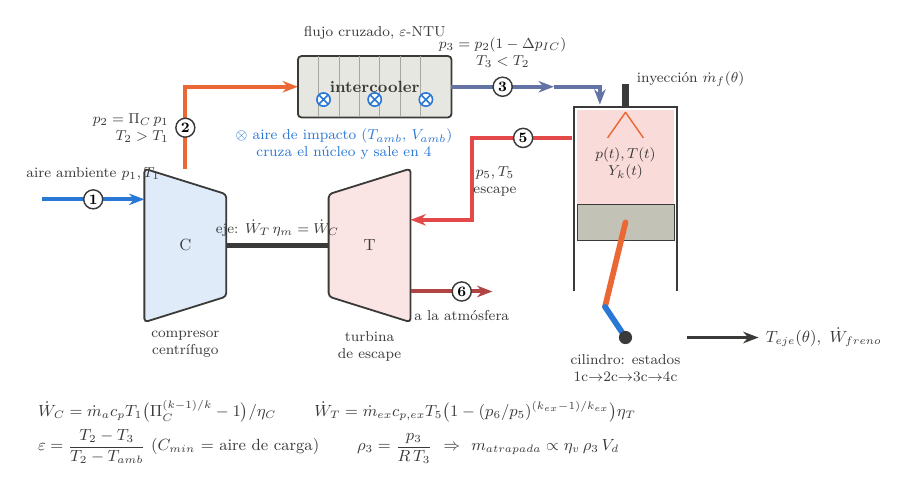

El cuadernillo recorre esa cadena en el orden en que la recorre el aire: mecanismo (§2), por qué $r_c$ alta (§3), admisión forzada (§4), química (§5), chorro y combustión (§6), emisiones (§7), fuerzas (§8), el motor completo carrera por carrera (§9) y la curva de potencia (§10).

## 2. El mecanismo biela-manivela con descentrado

El informe estudiantil resolvió un mecanismo de dos lazos por **lazos vectoriales** y el **método del jacobiano**. Aquí se aplica el mismo método al mecanismo de un solo lazo de un motor diésel real, con el **descentrado** $e$ del bulón que usan los fabricantes para reducir el golpeteo del pistón (ECN: $e=1.59$ mm).

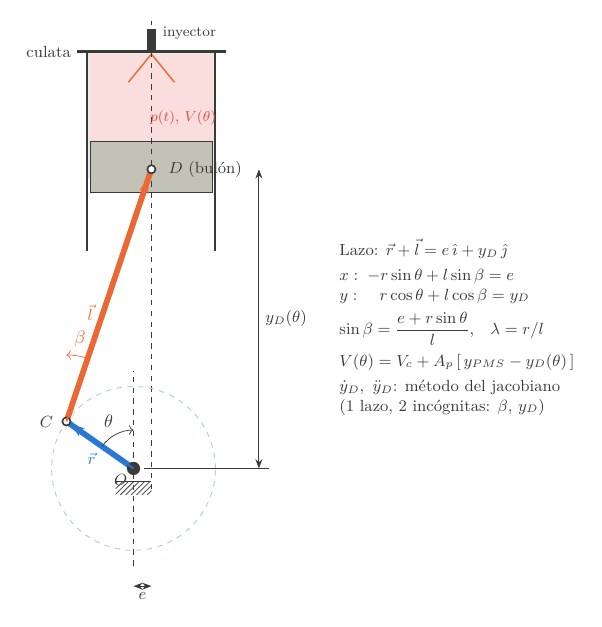

**Posición.** El lazo $\vec r+\vec l=e\,\hat\imath+y_D\,\hat\jmath$ da directamente

$$\sin\beta=\frac{e+r\sin\theta}{l},\qquad y_D=r\cos\theta+l\cos\beta,\qquad V(\theta)=V_c+A_p\left[y_{PMS}-y_D(\theta)\right]$$

**Velocidad y aceleración (jacobiano).** Derivando el lazo respecto al tiempo con $\dot\theta=\omega$:

$$\underbrace{\begin{bmatrix} l\cos\beta & 0\\ -l\sin\beta & -1\end{bmatrix}}_{\mathbf J}\begin{bmatrix}\dot\beta\\ \dot y_D\end{bmatrix}=\begin{bmatrix} r\omega\cos\theta\\ r\omega\sin\theta\end{bmatrix},\qquad
\mathbf J\begin{bmatrix}\ddot\beta\\ \ddot y_D\end{bmatrix}=\begin{bmatrix} -r\omega^2\sin\theta+l\dot\beta^2\sin\beta\\ -r\omega^2\cos\theta+l\dot\beta^2\cos\beta\end{bmatrix}$$

Para $e=0$ y $\lambda=r/l$ pequeño se recupera la aproximación clásica $\ddot y_D\approx -r\omega^2(\cos\theta+\lambda\cos 2\theta)$: el pistón no se mueve armónicamente y el **2.º armónico** vale $\lambda$ veces el primero.

In [3]:
# Cinemática completa del biela-manivela con descentrado (vectorizada en theta); omega constante (cuasi-estático)
def cinematica(th, w=0.0):
    th = np.asarray(th, float)
    sb = (EOFF + R_OC*np.sin(th))/ROD; b = np.arcsin(sb); cb = np.cos(b)
    y = R_OC*np.cos(th) + ROD*cb
    bd = R_OC*np.cos(th)*w/(ROD*cb)
    yd = -R_OC*np.sin(th)*w - ROD*np.sin(b)*bd
    bdd = (-R_OC*np.sin(th)*w**2 + ROD*np.sin(b)*bd**2)/(ROD*cb)
    ydd = -R_OC*np.cos(th)*w**2 - ROD*(np.sin(b)*bdd + np.cos(b)*bd**2)
    return dict(b=b, y=y, bd=bd, yd=yd, bdd=bdd, ydd=ydd)

Y_PMS = math.sqrt((ROD + R_OC)**2 - EOFF**2)          # posición del bulón en el PMS
def volumen(cad, Vc=VC):
    return Vc + A_P*(Y_PMS - cinematica(np.radians(cad))["y"])

print(f"cilindrada {A_P*STROKE*1e6:.1f} cm³ | V(PMS) = {volumen(0)*1e6:.2f} cm³ | V(PMI) = {volumen(180)*1e6:.1f} cm³ | "
      f"lambda = r/l = {R_OC/ROD:.3f} | e/r = {EOFF/R_OC:.3f}")

cilindrada 477.4 cm³ | V(PMS) = 32.22 cm³ | V(PMI) = 509.6 cm³ | lambda = r/l = 0.271 | e/r = 0.035


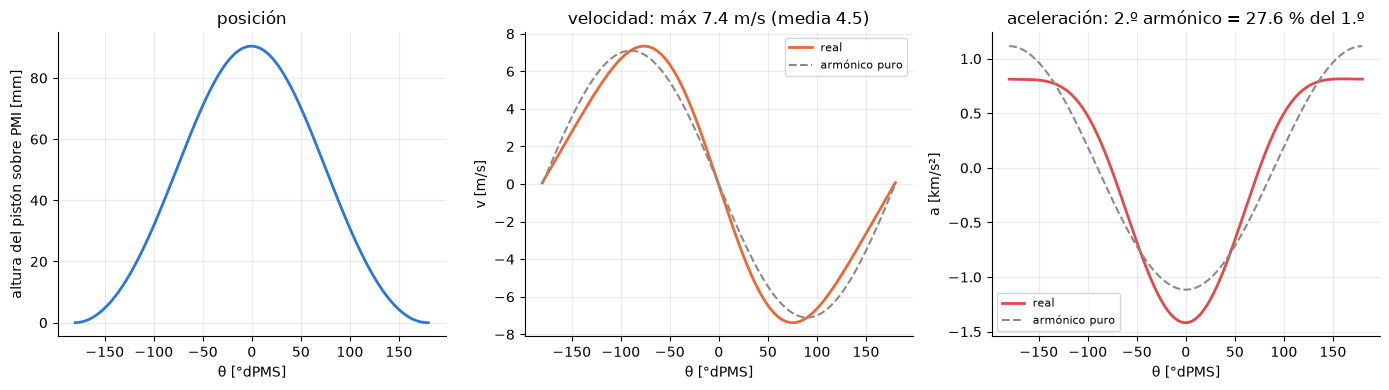

Cada grado de cigüeñal dura 111 µs a 1500 rpm: un retardo de ignición de 0.5 ms son 4.5°. Fuerza de inercia del pistón en el PMS: 0.8 kN.


Output()

In [4]:
# WIDGET 1 — cinemática del pistón: efecto de lambda = r/l, del descentrado y de las rpm
def widget_cinematica(lam=R_OC/ROD, e_mm=EOFF*1e3, rpm=1500):
    global ROD, EOFF
    ROD0, E0 = ROD, EOFF
    ROD, EOFF = R_OC/lam, e_mm*1e-3
    try:
        w = 2*np.pi*rpm/60; th = np.radians(np.arange(-180, 180.5, 0.5)); k = cinematica(th, w)
        a_arm = -R_OC*w**2*np.cos(th)
        F = np.fft.rfft(k["ydd"][:-1]); amp = np.abs(F)/len(F)
        fig, ax = plt.subplots(1, 3, figsize=(14, 4))
        ax[0].plot(np.degrees(th), (k["y"] - k["y"].min())*1e3, color=COL["manivela"], lw=2)
        ax[0].set_xlabel("θ [°dPMS]"); ax[0].set_ylabel("altura del pistón sobre PMI [mm]"); ax[0].set_title("posición")
        ax[1].plot(np.degrees(th), k["yd"], color=COL["biela"], lw=2, label="real")
        ax[1].plot(np.degrees(th), -R_OC*w*np.sin(th), "--", color=COL["gris"], label="armónico puro")
        ax[1].set_xlabel("θ [°dPMS]"); ax[1].set_ylabel("v [m/s]"); ax[1].legend(fontsize=8)
        ax[1].set_title(f"velocidad: máx {np.abs(k['yd']).max():.1f} m/s (media {2*STROKE*rpm/60:.1f})")
        ax[2].plot(np.degrees(th), k["ydd"]/1e3, color=COL["aviso"], lw=2, label="real")
        ax[2].plot(np.degrees(th), a_arm/1e3, "--", color=COL["gris"], label="armónico puro")
        ax[2].set_xlabel("θ [°dPMS]"); ax[2].set_ylabel("a [km/s²]"); ax[2].legend(fontsize=8)
        ax[2].set_title(f"aceleración: 2.º armónico = {amp[2]/amp[1]*100:.1f} % del 1.º")
        plt.tight_layout(); plt.show()
        us = 1/(6*rpm)*1e6
        print(f"Cada grado de cigüeñal dura {us:.0f} µs a {rpm} rpm: un retardo de ignición de 0.5 ms son {500/us:.1f}°. "
              f"Fuerza de inercia del pistón en el PMS: {MASAS['P']*abs(k['ydd'][len(th)//2])/1e3:.1f} kN.")
    finally:
        ROD, EOFF = ROD0, E0

display(interactive_output(widget_cinematica, {
    "lam": FloatSlider(R_OC/ROD, min=0.20, max=0.40, step=0.01, description="λ = r/l"),
    "e_mm": FloatSlider(EOFF*1e3, min=-5, max=5, step=0.25, description="e [mm]"),
    "rpm": IntSlider(1500, min=800, max=4500, step=100, description="rpm")}))

**Lectura.** El pistón pasa **más rápido** por la mitad superior de la carrera que por la inferior: la biela finita suma un 2.º armónico $\approx\lambda$ al movimiento. La aceleración en el PMS es $r\omega^2(1+\lambda)$ y crece con $\omega^2$, así que a 4000 rpm la inercia del pistón ya compite con la fuerza del gas. El descentrado de 1.6 mm casi no cambia la cinemática. Lo que hace es desplazar el instante en que el empuje lateral cambia de lado, y así suaviza el golpe del pistón contra la camisa (§8). La conversión de tiempo a grados es la clave de la combustión: **la química trabaja en milisegundos, el mecanismo en grados**.

## 3. ¿Por qué un diésel necesita $r_c$ alta? La ventana de autoencendido

El combustible se enciende si el **retardo de ignición** a las condiciones del PMS cabe en el tiempo disponible. Con compresión politrópica desde el cierre de admisión:

$$T_{PMS}\approx T_{IVC}\,r_c^{\,n-1},\qquad p_{PMS}\approx p_{IVC}\,r_c^{\,n},\qquad \tau_{ig}(T_{PMS},p_{PMS},\phi)\;\lesssim\;\frac{\Delta\theta_{disp}}{6N}$$

El retardo **cae exponencialmente** con $T$ ($\tau\propto p^{-a}e^{E_a/RT}$, Lección 8), así que unos pocos grados de $r_c$ deciden si el motor arranca en frío. Ajusta $r_c$, la temperatura y la presión de admisión: el widget calcula el retardo con **química detallada** en las condiciones de PMS que resultan.

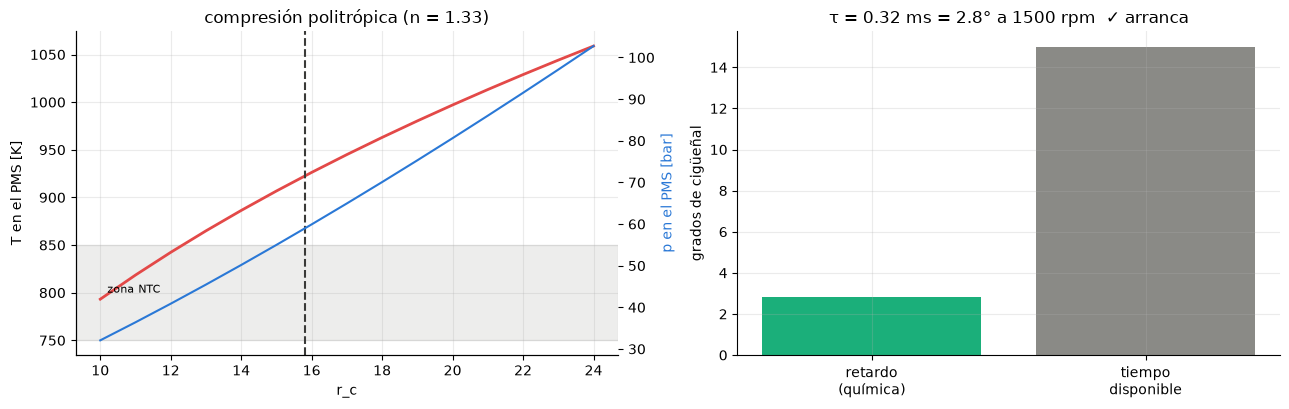

PMS: T = 922 K, p = 58.9 bar. El motor ECN opera con r_c = 15.8 y Sandia reporta T_PMS = 925 K.


Output()

In [5]:
# Retardo de ignición con química detallada (reactor homogéneo a volumen constante), n-heptano/aire
def tau_ignicion(T0, p0, phi=1.0, X=X_AIRE, t_max=0.05, historia=False):
    g = ct.Solution(MECH); g.TP = T0, p0; g.set_equivalence_ratio(phi, FUEL, X)
    r = ct.IdealGasReactor(g); net = ct.ReactorNet([r])
    ts, Ts, CH2O, OH = [], [], [], []
    iC, iO = g.species_index("ch2o"), g.species_index("oh")
    t1 = None
    while net.time < t_max:
        net.step()
        if historia:
            ts.append(net.time); Ts.append(r.T); CH2O.append(r.thermo.Y[iC]); OH.append(r.thermo.Y[iO])
        if r.T > T0 + 400:
            t1 = net.time; break
    if historia:
        return t1 if t1 else np.nan, np.array(ts), np.array(Ts), np.array(CH2O), np.array(OH)
    return t1 if t1 else np.nan

def widget_ventana(r_c=15.8, T_adm=353.0, p_adm=1.5, n=1.33):
    rr = np.linspace(10, 24, 15)
    T_pms = (T_adm + 18)*rr**(n - 1); p_pms = p_adm*1e5*rr**n
    T_sel = (T_adm + 18)*r_c**(n - 1); p_sel = p_adm*1e5*r_c**n
    tau = tau_ignicion(T_sel, p_sel)
    grados = tau*6*RPM0 if np.isfinite(tau) else np.nan
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].plot(rr, T_pms, color=COL["aviso"], lw=2); ax[0].axvline(r_c, color=COL["tinta"], ls="--")
    ax[0].axhspan(750, 850, color=COL["gris"], alpha=0.15); ax[0].text(10.2, 800, "zona NTC", fontsize=8)
    ax[0].set_xlabel("r_c"); ax[0].set_ylabel("T en el PMS [K]"); ax[0].set_title(f"compresión politrópica (n = {n})")
    ax0b = ax[0].twinx(); ax0b.plot(rr, p_pms/1e5, color=COL["manivela"], lw=1.5); ax0b.set_ylabel("p en el PMS [bar]", color=COL["manivela"]); ax0b.grid(False)
    lab = f"τ = {tau*1e3:.2f} ms = {grados:.1f}° a {RPM0} rpm" if np.isfinite(tau) else "no enciende en 50 ms"
    ok = np.isfinite(tau) and grados < 15
    ax[1].bar(["retardo\n(química)", "tiempo\ndisponible"], [grados if np.isfinite(grados) else 60, 15],
              color=[COL["control"] if ok else COL["aviso"], COL["gris"]])
    ax[1].set_ylabel("grados de cigüeñal"); ax[1].set_title(lab + ("  ✓ arranca" if ok else "  ✗ no arranca a tiempo"))
    plt.tight_layout(); plt.show()
    print(f"PMS: T = {T_sel:.0f} K, p = {p_sel/1e5:.1f} bar. El motor ECN opera con r_c = 15.8 y Sandia reporta T_PMS = 925 K.")

display(interactive_output(widget_ventana, {
    "r_c": FloatSlider(15.8, min=10, max=24, step=0.2, description="r_c", continuous_update=False),
    "T_adm": FloatSlider(353, min=250, max=420, step=5, description="T_adm [K]", continuous_update=False),
    "p_adm": FloatSlider(1.5, min=0.8, max=3.0, step=0.1, description="p_adm [bar]", continuous_update=False),
    "n": FloatSlider(1.33, min=1.25, max=1.38, step=0.01, description="n politrópico", continuous_update=False)}))

**Lectura.** Un arranque en frío (≈250 K de admisión, sin turbo) con $r_c=14$ deja el aire por debajo de ~800 K en el PMS y el retardo se dispara: por eso los diésel de baja compresión (Mazda Skyactiv-D, $r_c=14$) necesitan bujías de precalentamiento más activas. La sobrealimentación sube $p$ y $T$ a la vez y **acorta** el retardo, pero el intercooler la vuelve a alargar (§4). La compresión politrópica es una estimación: el modelo completo de §6 integra la compresión real con transferencia de calor.

## 4. Admisión forzada: compresor, intercooler y balance del turbocompresor

Los estados se numeran como en el diagrama de §1: 1 ambiente, 2 salida del compresor, 3 salida del intercooler (entrada al cilindro), 5 escape antes de la turbina, 6 salida de la turbina.

**Compresor** (eficiencia isentrópica $\eta_C$, aire real con CoolProp):

$$h_2=h_1+\frac{h_{2s}-h_1}{\eta_C},\qquad s_{2s}=s_1,\quad p_2=\Pi_C\,p_1,\qquad \dot W_C=\dot m_a\,(h_2-h_1)$$

**Intercooler** (flujo cruzado, ambos fluidos sin mezclar; $C_{min}$ = aire de carga):

$$\varepsilon=1-\exp\!\left[\frac{NTU^{0.22}}{C_r}\left(e^{-C_r NTU^{0.78}}-1\right)\right],\quad NTU=\frac{UA_s}{C_{min}},\quad T_3=T_2-\varepsilon\,(T_2-T_{amb}),\quad p_3=p_2(1-\Delta p_{IC})$$

**Turbina y balance de eje** (cierra el turbocompresor):

$$\dot W_T=\dot m_{ex}\,c_{p,ex}\,T_5\left[1-\left(\frac{p_6}{p_5}\right)^{\frac{k_{ex}-1}{k_{ex}}}\right]\eta_T,\qquad \eta_m\dot W_T=\dot W_C$$

**Lo que llega al cilindro.** La masa atrapada es $m_a\approx\rho_3 V_{IVC}$ con $\rho_3=p_3/(R\,T_3)$; con el combustible fijado por el límite de humo, $\lambda=m_a/(m_f\,AF_{st})$.

In [6]:
# Compresor (CoolProp), intercooler e-NTU y turbina
R_AIRE = 287.0
def compresor(p1, T1, PI, eta_c):
    h1 = CP.PropsSI("H", "T", T1, "P", p1, "Air"); s1 = CP.PropsSI("S", "T", T1, "P", p1, "Air")
    h2s = CP.PropsSI("H", "S", s1, "P", p1*PI, "Air"); h2 = h1 + (h2s - h1)/eta_c
    return CP.PropsSI("T", "H", h2, "P", p1*PI, "Air"), h2 - h1

def eps_flujo_cruzado(NTU, Cr):          # ambos fluidos sin mezclar (Incropera, Tabla 11.3)
    return 1 - np.exp((1/Cr)*NTU**0.22*(np.exp(-Cr*NTU**0.78) - 1))
def eps_carcasa_tubos(NTU, Cr):          # 1 paso por carcasa: la fórmula que usa el código de la entrega
    r = np.sqrt(1 + Cr**2)
    return 2/(1 + Cr + r*(1 + np.exp(-NTU*r))/(1 - np.exp(-NTU*r)))

def intercooler(T2, P2, mdot_h, Np=4, U=26.4, Nh=3, Din=0.1016, L_paso=0.6699, V_amb=10.0, phi_f=0.2, A_f=0.6274,
                cp_h=1025.3, cp_c=1013.0, T_amb=298.0, beta_dp=0.01, formula="cruzado"):
    mdot_c = 1.1802*phi_f*A_f*V_amb
    As = Nh*np.pi*Din*Np*L_paso
    Ch, Cc = mdot_h*cp_h, mdot_c*cp_c; Cmin, Cmax = min(Ch, Cc), max(Ch, Cc); Cr = Cmin/Cmax
    NTU = U*As/Cmin
    eps = eps_flujo_cruzado(NTU, Cr) if formula == "cruzado" else eps_carcasa_tubos(NTU, Cr)
    Q = eps*Cmin*(T2 - T_amb); T3 = T2 - Q/Ch; T4 = T_amb + Q/Cc; P3 = P2*(1 - beta_dp*Np)
    return dict(As=As, NTU=NTU, eps=eps, Q=Q, T3=T3, T4=T4, P3=P3, rho3=P3/(R_AIRE*T3), Cr=Cr)

def turbina_potencia(mdot_ex, T5, p5, p6, eta_t, cp_ex=1150.0, k_ex=1.33):
    return mdot_ex*cp_ex*T5*(1 - (p6/p5)**((k_ex - 1)/k_ex))*eta_t

# Modelo de Euler de la entrega, reproducido TAL CUAL (incluida la expresión de T2 de la entrega)
def compresor_euler_entrega(mdot_a, rho1=101325/(287*298), P1=101325.0, T1=298.0, N=150000, D1=0.0347, D2=0.049,
                            b1=0.006, b2=0.008, beta1=50.0, beta2=65.0, cp=1005.0, eta_c=0.80, g=9.81):
    r1, r2 = D1/2, D2/2; w = 2*np.pi*N/60; be1, be2 = np.radians(beta1), np.radians(beta2)
    v1n = (mdot_a/rho1)/(2*np.pi*r1*b1); v2n = (r1*b1)/(r2*b2)*v1n
    v1t = w*r1 - v1n/np.tan(be1); v2t = w*r2 - v2n/np.tan(be2)
    W = w*(r2*mdot_a*v2t - r1*mdot_a*v1t)
    HC = (1/g)*(w*r2*(w*r2 - v2n/np.tan(be2)) - w*r1*(w*r1 - v1n/np.tan(be1)))
    PI = (P1 + rho1*g*HC)/P1
    T2_entrega = T1 + W/(mdot_a*cp*eta_c)
    return dict(W=W, PI=PI, T2_entrega=T2_entrega, T2_euler=T1 + W/(mdot_a*cp),
                eta_s_implicita=T1*(PI**(0.4/1.4) - 1)/(T2_entrega - T1))

> 🎓 **Contribución estudiantil — Muñoz y Pedraza (2026).** Modelaron el compresor centrífugo con la **ecuación de Euler de turbomáquinas** (triángulos de velocidades, $\beta_1=50°$, $\beta_2=65°$, 150 000 rpm), un intercooler comercial (núcleo Spectra *bar-and-plate*) con ε-NTU y correlaciones de Dittus-Boelter y Hilpert, y su respuesta transitoria de primer orden ($\tau_{IC}=30$ s). Su conclusión central se conserva: **más pasos ⇒ más efectividad ⇒ mayor densidad de carga, a pesar de la caída de presión**. Aquí se reproducen sus resultados y se señalan, verificados numéricamente, cuatro puntos que conviene corregir. Las correcciones son la oportunidad de aprendizaje del módulo.

In [7]:
# Reproducción de la entrega (tablas de §3, §7 y §10 del cuadernillo estudiantil)
print("COMPRESOR (Euler), con el flujo de aire del acoplamiento: m_a = lambda_base AF_st Q/LHV")
for nom, AF, LHV_e, ref in [("ACPM B10", 14.6917, 42.43e6, (2.2117, 426.89, 17.941)), ("Biodiésel palma", 12.5577, 38.50e6, (2.1915, 424.74, 16.619))]:
    ma = 2*AF*250e3/LHV_e; e = compresor_euler_entrega(ma)
    print(f"  {nom:16s} m_a = {ma:.4f} kg/s -> Pi = {e['PI']:.4f} (entrega {ref[0]}), T2 = {e['T2_entrega']:.2f} K (entrega {ref[1]}), "
          f"W = {e['W']/1e3:.3f} kW (entrega {ref[2]})")
print("\nINTERCOOLER (ACPM B10, m_h = 0.1358 kg/s, T2 = 426.89 K):")
print(f"  {'Np':>3} {'eps entrega':>12} {'eps reproducida':>16} {'eps flujo cruzado':>18} {'T3 [K]':>8}")
for Np, ref in zip([2, 4, 6], [0.2138, 0.3785, 0.5058]):
    a = intercooler(426.89, 224.10e3, 0.1358, Np=Np, formula="carcasa"); b = intercooler(426.89, 224.10e3, 0.1358, Np=Np)
    print(f"  {Np:3d} {ref:12.4f} {a['eps']:16.4f} {b['eps']:18.4f} {a['T3']:8.2f}")
e = compresor_euler_entrega(2*14.6917*250e3/42.43e6)
print(f"\nEficiencia isentrópica IMPLÍCITA en (Pi, T2) de la entrega: {e['eta_s_implicita']:.3f} (se declaró eta_C = 0.80)")
print(f"T2 si todo el trabajo de Euler entra al aire: {e['T2_euler']:.1f} K (entrega: {e['T2_entrega']:.1f} K)")
print(f"Flujo de §7 de la entrega: m_h = W_C/(c_p (T2 - T1)) = {e['W']/(1025.3*(426.89 - 298)):.4f} kg/s (el W_C salió de m_a = 0.1731 kg/s)")

COMPRESOR (Euler), con el flujo de aire del acoplamiento: m_a = lambda_base AF_st Q/LHV
  ACPM B10         m_a = 0.1731 kg/s -> Pi = 2.2117 (entrega 2.2117), T2 = 426.89 K (entrega 426.89), W = 17.941 kW (entrega 17.941)
  Biodiésel palma  m_a = 0.1631 kg/s -> Pi = 2.1915 (entrega 2.1915), T2 = 424.74 K (entrega 424.74), W = 16.619 kW (entrega 16.619)

INTERCOOLER (ACPM B10, m_h = 0.1358 kg/s, T2 = 426.89 K):
   Np  eps entrega  eps reproducida  eps flujo cruzado   T3 [K]
    2       0.2138           0.2138             0.2130   399.34
    4       0.3785           0.3784             0.3774   378.12
    6       0.5058           0.5057             0.5053   361.71

Eficiencia isentrópica IMPLÍCITA en (Pi, T2) de la entrega: 0.589 (se declaró eta_C = 0.80)
T2 si todo el trabajo de Euler entra al aire: 401.1 K (entrega: 426.9 K)
Flujo de §7 de la entrega: m_h = W_C/(c_p (T2 - T1)) = 0.1358 kg/s (el W_C salió de m_a = 0.1731 kg/s)


**Cuatro puntos a corregir (verificados arriba):**

| # | En la entrega | Qué pasa | Efecto |
|---|---|---|---|
| 1 | $T_2=T_1+\dot W_{Euler}/(\dot m c_p\,\eta_C)$ | El trabajo de Euler ya es todo el trabajo que entra al aire; dividir por $\eta_C$ cuenta las pérdidas dos veces, y el $\Delta p$ sale de una altura ideal sin pérdidas | $\eta_s$ implícita = 0.59, no 0.80; $T_2$ ~26 K de más |
| 2 | Texto: flujo cruzado; código: $\varepsilon$ de carcasa y tubos | Fórmula de otra configuración | ≤0.4 % con $C_r\approx0.09$: pequeño en número, pero es un error conceptual |
| 3 | $\dot m_h$ de §7 despejado de $\dot W_C$ con el $\Delta T$ inflado | Da 0.1358 kg/s cuando el compresor se resolvió con 0.1731 kg/s | Dos $T_3$ distintas para el mismo diseño $N_p=6$ (361.9 K y 372.3 K) |
| 4 | Cinética global a $T$ **fija** de 1200 K | El intercooler solo actúa vía la concentración de O₂ | No puede aparecer el efecto dominante: carga más fría ⇒ $T_{PMS}$ menor ⇒ **retardo mayor**, más premezcla y menos NOx (widget siguiente y §7) |

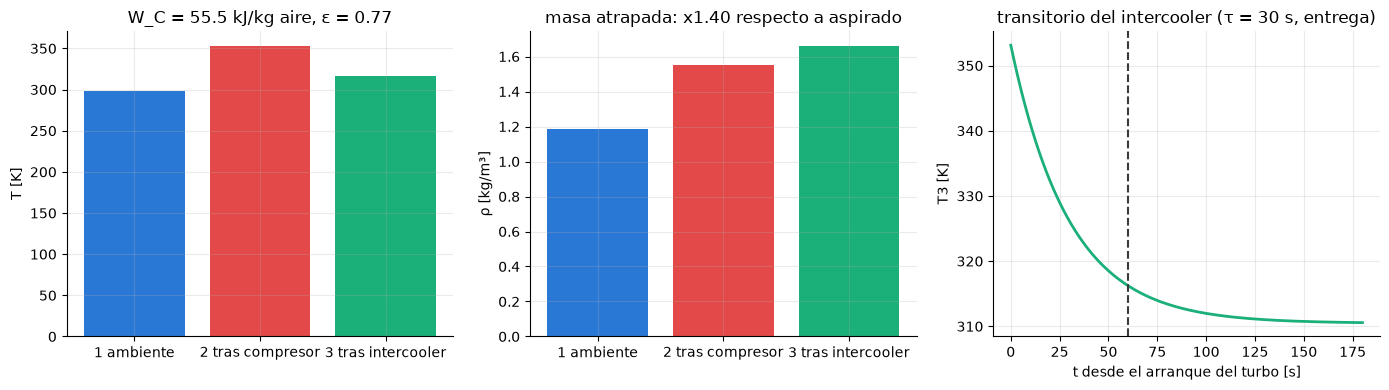

sin intercooler : T_PMS ≈  880 K, p_PMS ≈  51.0 bar -> retardo de ignición 0.356 ms ( 3.2° a 1500 rpm)
con intercooler : T_PMS ≈  793 K, p_PMS ≈  49.0 bar -> retardo de ignición 0.916 ms ( 8.2° a 1500 rpm)
El intercooler da más aire (más par posible) y ALARGA el retardo: más combustible premezclado y menos NOx.


Output()

In [8]:
# WIDGET 3 — tren de admisión: compresor -> intercooler -> cilindro, y lo que eso le hace al autoencendido
def widget_admision(PI=1.55, eta_C=0.72, Np=4, V_amb=10.0, t_s=60.0):
    p1, T1 = 1.013e5, 298.0
    T2, wc = compresor(p1, T1, PI, eta_C)
    V_ivc = volumen(IVC)
    m_dot = 4*1.8*V_ivc*1500/120          # flujo de aire aproximado de un 4 cil. a 1500 rpm [kg/s] (orden de magnitud)
    ic = intercooler(T2, p1*PI, m_dot, Np=Np, V_amb=V_amb)
    tau_IC = 30.0; T3_t = ic["T3"] + (T2 - ic["T3"])*np.exp(-t_s/tau_IC)
    rho1, rho2, rho3 = p1/(R_AIRE*T1), p1*PI/(R_AIRE*T2), ic["P3"]/(R_AIRE*T3_t)
    # autoencendido en el PMS (r_c efectiva del motor ECN ~13.7, n = 1.33)
    taus = []
    for T_in, p_in in [(T2, p1*PI), (T3_t, ic["P3"])]:
        Tp, pp = (T_in + 18)*13.7**0.33, p_in*13.7**1.33
        taus.append((Tp, pp, tau_ignicion(Tp, pp)))
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    est = ["1 ambiente", "2 tras compresor", "3 tras intercooler"]
    ax[0].bar(est, [T1, T2, T3_t], color=[COL["frio"], COL["caliente"], COL["control"]]); ax[0].set_ylabel("T [K]")
    ax[0].set_title(f"W_C = {wc/1e3:.1f} kJ/kg aire, ε = {ic['eps']:.2f}")
    ax[1].bar(est, [rho1, rho2, rho3], color=[COL["frio"], COL["caliente"], COL["control"]]); ax[1].set_ylabel("ρ [kg/m³]")
    ax[1].set_title(f"masa atrapada: x{rho3/rho1:.2f} respecto a aspirado")
    t = np.linspace(0, 180, 200)
    ax[2].plot(t, ic["T3"] + (T2 - ic["T3"])*np.exp(-t/tau_IC), color=COL["control"], lw=2)
    ax[2].axvline(t_s, color=COL["tinta"], ls="--"); ax[2].set_xlabel("t desde el arranque del turbo [s]"); ax[2].set_ylabel("T3 [K]")
    ax[2].set_title("transitorio del intercooler (τ = 30 s, entrega)")
    plt.tight_layout(); plt.show()
    for nom, (Tp, pp, tt) in zip(["sin intercooler", "con intercooler"], taus):
        print(f"{nom:16s}: T_PMS ≈ {Tp:4.0f} K, p_PMS ≈ {pp/1e5:5.1f} bar -> retardo de ignición {tt*1e3:5.3f} ms ({tt*9000:4.1f}° a 1500 rpm)")
    print("El intercooler da más aire (más par posible) y ALARGA el retardo: más combustible premezclado y menos NOx.")

display(interactive_output(widget_admision, {
    "PI": FloatSlider(1.55, min=1.0, max=2.6, step=0.05, description="Π_C", continuous_update=False),
    "eta_C": FloatSlider(0.72, min=0.55, max=0.82, step=0.01, description="η_C", continuous_update=False),
    "Np": IntSlider(4, min=1, max=8, description="pasos IC", continuous_update=False),
    "V_amb": FloatSlider(10, min=2, max=30, step=1, description="V_aire [m/s]", continuous_update=False),
    "t_s": FloatSlider(60, min=0, max=180, step=5, description="t [s]", continuous_update=False)}))

## 5. Química del autoencendido: por qué n-heptano, y qué es la "llama fría"

El diésel real es una mezcla de cientos de hidrocarburos. Para la química se usa una **molécula sustituta** que reproduzca lo que importa en el motor: el **retardo de ignición**, medido por el número de cetano (NC). El combustible del ensayo ECN (DPRF58) tiene NC = 58 y el **n-heptano** NC ≈ 56. Se probó también el n-dodecano (NC ≈ 74, mecanismo de 53 especies) y enciende demasiado rápido: 0.10-0.27 ms a 900 K y 48 bar, contra 0.30-0.57 ms del n-heptano y 0.50-0.67 ms medidos en el piloto del motor (este valor incluye ~0.1-0.2 ms de atomización y evaporación).

Los alcanos de cadena larga encienden **en dos etapas** (Lección 8, mecanismo radicalario):

- **Llama fría (≈700-850 K).** El O₂ se adiciona al radical alquilo ($R+O_2\rightleftharpoons RO_2$), que se isomeriza y ramifica produciendo **formaldehído** (CH₂O) y un salto de unos 100 K.
- **NTC (coeficiente negativo de temperatura).** Al subir $T$, el equilibrio $R+O_2\rightleftharpoons RO_2$ se desplaza a la izquierda y la ramificación de baja temperatura **se apaga**: en ese rango, más caliente enciende **más lento**.
- **Ignición principal (>1000 K).** La ramificación $H+O_2\to OH+O$ dispara la temperatura; el **OH** marca la llama caliente.

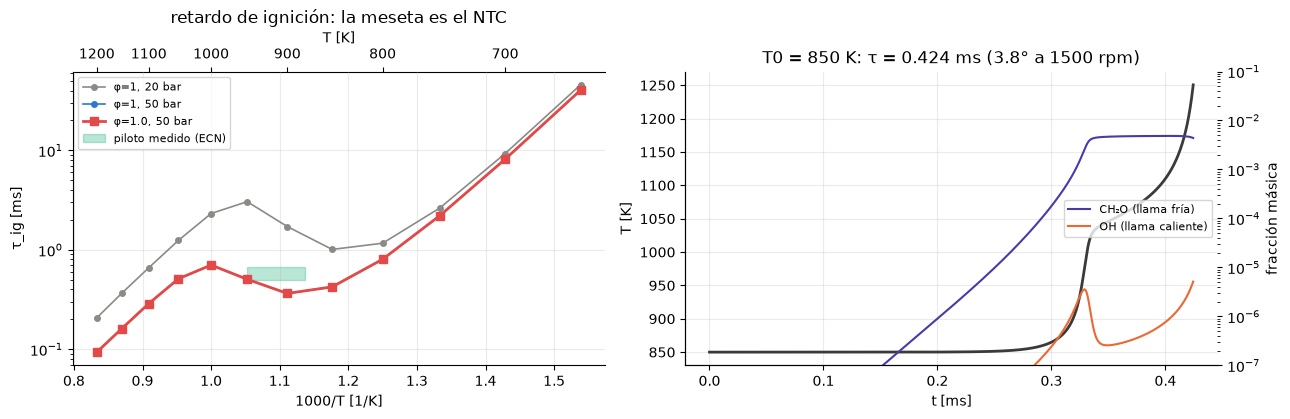

Output()

In [9]:
# WIDGET 4 — retardo de ignición del n-heptano: dos etapas, NTC y contraste con lo medido en el motor
T_GRID = np.arange(650, 1201, 50.0)
_tau_base = {pb: np.array([tau_ignicion(T, pb*1e5) for T in T_GRID]) for pb in (20, 50)}

def widget_ignicion(p_bar=50, phi=1.0, T0=850):
    tau, ts, Ts, ch2o, oh = tau_ignicion(T0, p_bar*1e5, phi, historia=True)
    curva = np.array([tau_ignicion(T, p_bar*1e5, phi) for T in T_GRID])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
    for pb, cc in [(20, COL["gris"]), (50, COL["manivela"])]:
        ax[0].semilogy(1000/T_GRID, _tau_base[pb]*1e3, "o-", color=cc, lw=1.2, ms=4, label=f"φ=1, {pb} bar")
    ax[0].semilogy(1000/T_GRID, curva*1e3, "s-", color=COL["aviso"], lw=2, label=f"φ={phi}, {p_bar} bar")
    ax[0].fill_between([1000/950, 1000/880], 0.50, 0.67, color=COL["control"], alpha=0.3, label="piloto medido (ECN)")
    ax[0].set_xlabel("1000/T [1/K]"); ax[0].set_ylabel("τ_ig [ms]"); ax[0].legend(fontsize=8)
    ax[0].set_title("retardo de ignición: la meseta es el NTC")
    sec = ax[0].secondary_xaxis("top", functions=(lambda x: 1000/np.maximum(x, 1e-3), lambda T: 1000/np.maximum(T, 1e-3)))
    sec.set_xlabel("T [K]")
    if len(ts):
        ax[1].plot(ts*1e3, Ts, color=COL["tinta"], lw=2); ax[1].set_xlabel("t [ms]"); ax[1].set_ylabel("T [K]")
        a2 = ax[1].twinx(); a2.semilogy(ts*1e3, np.maximum(ch2o, 1e-9), color=COL["CH2O"], label="CH₂O (llama fría)")
        a2.semilogy(ts*1e3, np.maximum(oh, 1e-9), color=COL["OH"], label="OH (llama caliente)"); a2.set_ylim(1e-7, 1e-1)
        a2.set_ylabel("fracción másica"); a2.grid(False); a2.legend(fontsize=8, loc="center right")
        ax[1].set_title(f"T0 = {T0} K: τ = {tau*1e3:.3f} ms ({tau*9000:.1f}° a 1500 rpm)")
    plt.tight_layout(); plt.show()

display(interactive_output(widget_ignicion, {
    "p_bar": IntSlider(50, min=10, max=120, step=10, description="p [bar]", continuous_update=False),
    "phi": FloatSlider(1.0, min=0.3, max=3.0, step=0.1, description="φ", continuous_update=False),
    "T0": IntSlider(850, min=650, max=1200, step=25, description="T0 [K]", continuous_update=False)}))

**Lectura.** Mira la curva de 50 bar: entre ~750 y ~900 K el retardo casi **no baja** al subir la temperatura. Esa meseta es el NTC. Con $T_0$ = 750 K verás la llama fría: el CH₂O sube y la temperatura da un primer escalón **antes** de que aparezca el OH. Las mezclas **ricas** ($\phi$ = 2-3) encienden antes que las estequiométricas. Por eso, en el chorro, la ignición empieza en la zona rica y no en la llama de difusión. Los ~0.5 ms medidos en el piloto caen justo donde el n-heptano predice.

## 6. El chorro y la combustión: un modelo de dos zonas que se valida contra el motor real

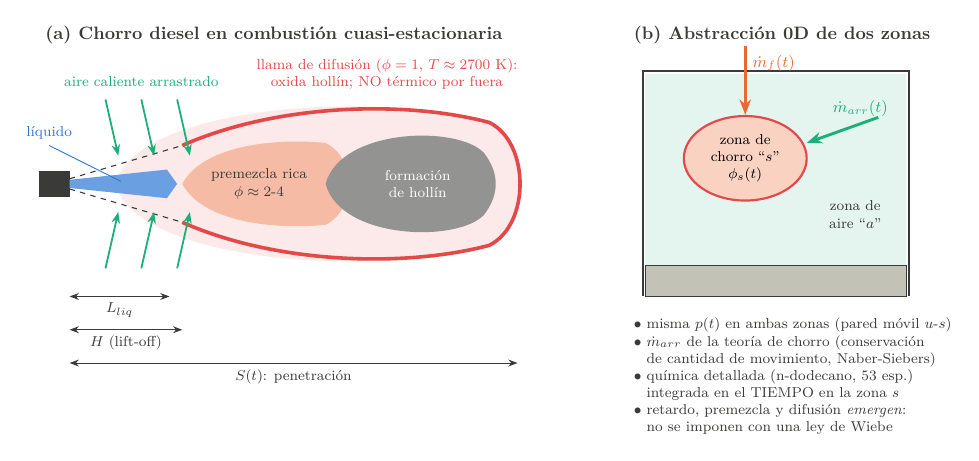

El combustible entra como un **chorro** a ~420 m/s (800 bar). Se atomiza, **arrastra aire caliente**, se evapora (y se enfría) y se mezcla. Cuando la mezcla ha "madurado" lo suficiente se autoenciende (premezcla). Después quema a la velocidad con la que el aire llega a la llama de difusión. El modelo 0D tiene una **zona de aire** $A$ y una **zona de chorro por cada inyección** (piloto y principal). Todas comparten la presión $p(t)$ y cada zona integra su energía y sus 88 especies en el **tiempo**:

$$\frac{d(m_ku_k)}{dt}=-p\frac{dV_k}{dt}-\dot Q_{w,k}+\sum_{entra}\dot m\,h,\qquad \frac{dY_{i,k}}{dt}=\frac{\dot\omega_iW_i}{\rho_k}+\text{(mezcla de lo que entra)}$$

**Penetración (Naber y Siebers, 1996)** y **arrastre por conservación de cantidad de movimiento (Hiroyasu)**, para cada inyección:

$$\tilde S=\left[\tilde t^{-n}+\tilde t^{-n/2}\right]^{-1/n},\quad \tilde S=\frac{S}{x^+},\ \tilde t=\frac{t}{t^+};\qquad m_{a}(t)=C_{ent}\,m_f(t)\left(\frac{u_0}{\dot S}-1\right),\quad u_0=C_v\sqrt{2\Delta p/\rho_f}$$

- **Choque con la pared.** Después de chocar con la pared del bowl ($S>S_w=26$ mm, calculado con el perfil del pistón y la geometría del inyector del ECN), la tasa de arrastre se multiplica por $C_w$, porque los chorros de pared se funden y el aire del bowl ya está usado.
- **Piloto y principal.** El chorro principal recorre la región que ocupa el piloto: arrastra de la zona piloto la fracción $\chi=m_{pil}/(m_{pil}+m_{princ})$ y del aire el resto.
- **Evaporación.** El combustible entra con la entalpía del líquido, $h_f=h_{vap}(350\,K)-h_{fg}$, así que el enfriamiento por evaporación está en el balance de energía sin término aparte.
- **Pérdidas de calor.** Correlación de Woschni.

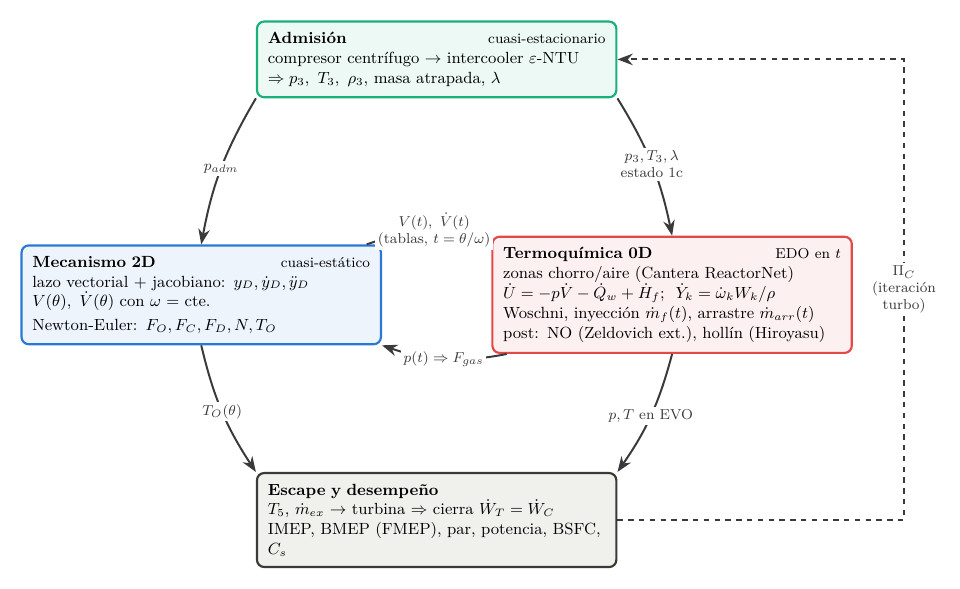

In [10]:
# Inyección medida, chorro de Naber-Siebers y agrupación de eventos (piloto / principal)
def perfil_inyeccion(caso):
    c = ECN["casos"][caso]
    ca = np.array(c["inj_cad"]); m = np.clip(np.array(c["inj_gs"]), 0, None)*1e-3   # kg/s
    m[m < 0.5e-3] = 0.0
    return ca, m

def agrupar_eventos(ca, m, wdeg, m_min=0.1e-6):
    on = m > 1e-3; idx = np.where(np.diff(on.astype(int)) != 0)[0]
    ev = [(ca[idx[k]+1], ca[idx[k+1]]) for k in range(0, len(idx) - 1, 2)]
    res = []
    for a, b in ev:
        sel = (ca >= a - 0.3) & (ca <= b + 0.3); mm = np.trapezoid(m[sel], ca[sel]/wdeg)
        if res and (mm < m_min or a - res[-1][1] < 2.5): res[-1] = (res[-1][0], b)   # rebote de la aguja
        else: res.append((a, b))
    return res

def chorro(dp, rho_a, d=G["d_hole"], Cv=0.9, Ca=0.86, a=0.66):
    U = Cv*math.sqrt(2*dp/RHO_F)
    tan = 0.26*((rho_a/RHO_F)**0.19 - 0.0043*math.sqrt(RHO_F/rho_a))
    xp = math.sqrt(RHO_F/rho_a)*math.sqrt(Ca)*d/(a*tan)
    return U, tan, xp, xp/U
def penetracion(t, xp, tp, n=2.2):
    tt = max(t, 1e-12)/tp
    return xp*((1/tt)**n + (1/tt**0.5)**n)**(-1/n)

In [11]:
# Ciclo cerrado (IVC -> EVO): zona de aire + una zona de chorro por inyección (Cantera ReactorNet, EDO en el tiempo)
def ciclo_diesel(caso="SSE-7", rpm=None, p_ivc=None, T_ivc=371.0, X_aire=X_ECN, C_ent=2.0, C_w=0.3, S_w=26e-3,
                 Vc=37.48e-6, T_pared=420.0, swirl=0.0, quimica=True, dphi=0.5, rtol=1e-6, cad_fin=EVO,
                 desplazar_inyeccion=0.0, p_iny=None, combustible=True, perfil=None, F_NUCLEO=5e-3):
    rpm = RPM0 if rpm is None else rpm
    p_iny = OP["p_inj"] if p_iny is None else p_iny
    w = 2*math.pi*rpm/60; wdeg = math.degrees(w)
    c = ECN["casos"][caso]
    if p_ivc is None: p_ivc = float(np.interp(IVC, c["cad"], c["p_kPa"]))*1e3
    DPH = 0.05; ph = np.arange(IVC, cad_fin + 2.0, DPH); k = cinematica(np.radians(ph), w)
    TV = (-k["yd"]).tolist(); TAW = (2*A_P + math.pi*BORE*(Y_PMS - k["y"] + Vc/A_P)).tolist()
    def tab(T, t):
        x = t*wdeg/DPH; i = int(x); f = x - i
        return T[i]*(1 - f) + T[i+1]*f
    V_ivc = Vc + A_P*(Y_PMS - k["y"][0]); Vd = A_P*STROKE
    ca_i, m_i = perfil_inyeccion(caso) if perfil is None else perfil
    ca_i = np.asarray(ca_i) + desplazar_inyeccion; m_i = np.asarray(m_i)*(1.0 if combustible else 0.0)
    ev = agrupar_eventos(ca_i, m_i, wdeg) if combustible else []
    t_i = (ca_i - IVC)/wdeg
    cum = np.concatenate([[0.0], np.cumsum(0.5*(m_i[1:] + m_i[:-1])*np.diff(t_i))])
    ev_t = [((a - IVC)/wdeg, (b - IVC)/wdeg) for a, b in ev]
    lim = [ev_t[j+1][0] if j + 1 < len(ev_t) else 1e9 for j in range(len(ev_t))]
    def mdot_f_evento(j):
        ta = ev_t[j][0] - 0.3/wdeg; tb = lim[j] - 0.3/wdeg
        return lambda t: 0.0 if (t < ta or t >= tb or t > t_i[-1] or t < t_i[0]) else float(np.interp(t, t_i, m_i))
    def mf_hasta(t, j):
        ta = ev_t[j][0] - 0.3/wdeg; tb = lim[j] - 0.3/wdeg
        return float(np.interp(min(t, tb), t_i, cum) - np.interp(ta, t_i, cum)) if t > ta else 0.0
    gA = ct.Solution(MECH); gA.TPX = T_ivc, p_ivc, X_aire
    A = ct.IdealGasReactor(gA, clone=False); A.volume = V_ivc*(1 - F_NUCLEO*max(len(ev), 1)); A.chemistry_enabled = quimica
    Z = []
    for j in range(len(ev)):
        g = ct.Solution(MECH); g.TPX = T_ivc, p_ivc, X_aire
        z = ct.IdealGasReactor(g, clone=False); z.volume = V_ivc*F_NUCLEO; z.chemistry_enabled = quimica; Z.append(z)
    todas = [A] + Z; m_aire = sum(r.mass for r in todas)
    env = ct.Reservoir(ct.Solution(MECH))
    gF = ct.Solution(MECH); gF.TPX = 350.0, p_ivc, FUEL + ":1"; gF.HP = gF.enthalpy_mass - H_FG, p_ivc
    resF = ct.Reservoir(gF)
    ct.Wall(A, env, A=A_P, velocity=lambda t: tab(TV, t))                 # pistón
    for z in Z: ct.Wall(z, A, A=1.0, K=1e-4)                              # misma presión en todas las zonas
    Sp = 2*STROKE*rpm/60; v_rem = swirl*w*BORE/2; cache = {"p": -1.0, "h": 0.0}
    def h_w():                                                            # Woschni (con swirl opcional)
        p = A.thermo.P
        if p == cache["p"]: return cache["h"]
        V = sum(r.volume for r in todas); m = sum(r.mass for r in todas); Tm = sum(r.mass*r.T for r in todas)/m
        pmot = p_ivc*(V_ivc/V)**1.36
        wg = (2.28 + 0.308*v_rem/Sp)*Sp + 3.24e-3*Vd*T_ivc/(p_ivc*V_ivc)*max(p - pmot, 0.0)
        h = 3.26*BORE**-0.2*(p/1e3)**0.8*Tm**-0.55*wg**0.8
        cache["p"], cache["h"] = p, h
        return h
    def q_zona(r):
        return lambda t: h_w()*tab(TAW, t)*(r.volume/sum(rr.volume for rr in todas))*(r.T - T_pared)
    for r in todas: ct.Wall(r, env, A=1.0, Q=q_zona(r))
    fz = [mdot_f_evento(j) for j in range(len(ev))]
    for j, z in enumerate(Z): ct.MassFlowController(resF, z, mdot=fz[j])
    def tasa(j):                                                          # arrastre de Hiroyasu del chorro j
        def r(t):
            if A.mass < 2e-2*m_aire: return 0.0
            U, tan, xp, tp = chorro(max(p_iny - A.thermo.P, 1e5), A.thermo.density); hh = 2e-6; ta = ev_t[j][0]
            if t <= ta + hh: return 0.0
            def term(tt):
                ts = tt - ta; s1 = penetracion(ts, xp, tp); sd = (s1 - penetracion(max(ts - 1e-7, 1e-12), xp, tp))/1e-7
                return mf_hasta(tt, j)*max(U/max(sd, 1e-3) - 1.0, 0.0), s1
            m1, s1 = term(t); m0, _ = term(t - hh)
            return C_ent*max(m1 - m0, 0.0)/hh*(C_w if s1 > S_w else 1.0)
        return r
    rates = [tasa(j) for j in range(len(ev))]
    chi = lambda j: Z[j-1].mass/(Z[j-1].mass + Z[j].mass)
    def de_aire(j):
        return lambda t: 0.0 if (j + 1 < len(ev_t) and t >= ev_t[j+1][0]) else rates[j](t)*((1 - chi(j)) if j > 0 else 1.0)
    def de_previa(j):
        return lambda t: 0.0 if (j + 1 < len(ev_t) and t >= ev_t[j+1][0]) else rates[j](t)*chi(j)
    for j, z in enumerate(Z):
        ct.MassFlowController(A, z, mdot=de_aire(j))
        if j > 0: ct.MassFlowController(Z[j-1], z, mdot=de_previa(j))
    net = ct.ReactorNet(todas); net.rtol = rtol; net.atol = 1e-15
    cads = np.append(np.arange(IVC, cad_fin, dphi), cad_fin)
    iF = gA.species_index(FUEL); idx = {s: gA.species_index(s) for s in ["o2", "oh", "ch2o", "co", "c2h2", "o", "h", "n2"]}
    out = {kk: [] for kk in ["cad", "V", "p", "TA", "hrr", "Qw", "Uint", "Hin", "mf_iny", "mF"]}
    zk = ["T", "m", "V", "phi", "YF", "YO2", "YOH", "YCH2O", "YCO", "YC2H2", "XO2"]
    zon = {kk: [[] for _ in Z] for kk in zk}
    t0 = time.time(); Qw = Hin = mfi = 0.0; prev = None; hF = gF.enthalpy_mass
    for cad in cads:
        t = math.radians(cad - IVC)/w
        if t > 0: net.advance(t)
        V = sum(r.volume for r in todas)
        q = sum(h_w()*tab(TAW, t)*(r.volume/V)*(r.T - T_pared) for r in todas); mf = sum(f(t) for f in fz)
        if prev is not None:
            dt = t - prev[0]; Qw += 0.5*(q + prev[1])*dt; Hin += 0.5*(mf + prev[2])*dt*hF; mfi += 0.5*(mf + prev[2])*dt
        prev = (t, q, mf)
        out["cad"].append(cad); out["V"].append(V); out["p"].append(A.thermo.P); out["TA"].append(A.T)
        out["hrr"].append(sum(r.thermo.heat_release_rate*r.volume for r in todas)/wdeg)
        out["Qw"].append(Qw); out["Uint"].append(sum(r.mass*r.thermo.int_energy_mass for r in todas))
        out["Hin"].append(Hin); out["mf_iny"].append(mfi); out["mF"].append(sum(r.mass*r.thermo.Y[iF] for r in todas))
        for j, z in enumerate(Z):
            Y = z.thermo.Y; mfj = mf_hasta(t, j)
            for kk, v in [("T", z.T), ("m", z.mass), ("V", z.volume), ("phi", mfj/max(z.mass - mfj, 1e-12)/FAR_ST if mfj > 1e-9 else 0.0),
                          ("YF", Y[iF]), ("YO2", Y[idx["o2"]]), ("YOH", Y[idx["oh"]]), ("YCH2O", Y[idx["ch2o"]]),
                          ("YCO", Y[idx["co"]]), ("YC2H2", Y[idx["c2h2"]]), ("XO2", z.thermo.X[idx["o2"]])]:
                zon[kk][j].append(v)
    o = {kk: np.array(v) for kk, v in out.items()}
    o["zonas"] = {kk: np.array(v) for kk, v in zon.items()}
    W = np.trapezoid(o["p"], o["V"])
    o.update(caso=caso, rpm=rpm, T_ivc=T_ivc, p_ivc=p_ivc, m_aire=m_aire, m_iny=mfi, cpu=time.time() - t0,
             eventos=[(float(a), float(b)) for a, b in ev], W=W, Vd=Vd, imep_g=W/Vd, Vc=Vc, X_aire=X_aire)
    o["cierre_1a_ley"] = (o["Uint"][0] + o["Hin"][-1] - o["Uint"][-1] - o["Qw"][-1] - W)/max(abs(W), 1.0)
    return o

### Calibración y validación contra el ECN (la figura de referencia)

Las constantes se ajustan **por etapas y con datos distintos**, y la validación se hace con datos que **no** se usaron en ningún ajuste:

| Etapa | Qué se ajusta | Contra qué dato | Resultado |
|---|---|---|---|
| 1. Compresión | $V_c$ efectivo (ranuras, *blow-by* y pistón de cuarzo del motor óptico) | presión **sin combustión** medida (SSE+2, −100 a +4°) | $V_c$ = 37.5 cm³ ($r_{c,ef}$ = 13.7), rms 0.49 bar |
| 2. Temperatura | $T_{IVC}$ | $T_{PMS}$ = 925 K reportada por Sandia | $T_{IVC}$ = 371 K |
| 3. Mezcla | $C_{ent}$ (chorro libre) | retardo del **piloto** de SSE−7 | $C_{ent}$ = 2.0 |
| 4. Mezcla | $C_w$ (chorros de pared) | pico de liberación de calor de SSE−7 | $C_w$ = 0.30 |
| **Validación** | nada | **SSE−17 y SSE+2** completos | ver figura |

Se probaron alternativas y se descartaron por evidencia (detalle en la bitácora del proyecto):
- **Arrastre por volumen del cono.** Diluye la zona de chorro hasta $\phi\approx0.2$ y nunca enciende: actúa como un reactor bien mezclado cuyo tiempo de residencia es menor que el retardo.
- **Una sola zona de chorro.** El principal cae sobre los productos calientes del piloto y quema sin retardo, con el doble del pico medido.
- **Woschni con corrección de remolino.** Iguala la pérdida estimada por Sandia (215 J), pero el piloto tardío ya no enciende y la calibración no se transfiere.

In [12]:
# Post-proceso de emisiones: NO térmico en paquetes de gas quemado a phi=1 y hollín de Hiroyasu
def emisiones(o, X_aire=None, LHV=44.6e6, A_f=150.0, E_f=6295.0, A_o=1.0e4, E_o=7070.0, cada=2):
    X_aire = o.get("X_aire", X_ECN) if X_aire is None else X_aire
    cad, p, TA = o["cad"], o["p"], o["TA"]; t = np.radians(cad - cad[0])/(2*math.pi*o["rpm"]/60)
    g = ct.Solution(MECH); gf = ct.Solution(MECH); gf.TPX = 350.0, 50e5, FUEL + ":1"; h_liq = gf.enthalpy_mass - H_FG
    dmb = np.clip(o["hrr"], 0, None)*np.gradient(cad)/LHV*(1 + 1/FAR_ST)    # masa de productos estequiométricos
    paq = []
    for i in range(0, len(cad), cada):
        mb = dmb[i:i+cada].sum()
        if mb < 1e-9 or o["hrr"][i] <= 0.5: continue
        g.TPX = TA[i], p[i], X_aire; ha = g.enthalpy_mass
        g.set_equivalence_ratio(1.0, FUEL, X_aire); Yf = g[FUEL].Y[0]
        g.HPY = Yf*h_liq + (1 - Yf)*ha, p[i], g.Y; g.equilibrate("HP")          # llama adiabática de difusión
        paq.append((i, mb, g.T, p[i], g["o2"].X[0], g["n2"].X[0], g.cp_mass/g.cv_mass, g.mean_molecular_weight))
    no = np.zeros(len(cad))
    for (i0, mb, Tf, pf, xo2, xn2, gam, W) in paq:
        T = Tf*(p[i0:]/pf)**((gam - 1)/gam); c = p[i0:]/(8.314*T)*1e-6               # mol/cm3
        O = 397.0*T**-0.5*np.sqrt(xo2*c)*np.exp(-31090.0/T)                          # [O] de equilibrio (mol/cm3)
        r = 2*7.6e13*np.exp(-38000.0/T)*O*xn2*c                                       # d[NO]/dt (Zeldovich)
        dno = r*mb/(p[i0:]*W*1e-3/(8.314*T))*1e6*0.030
        no[i0:] += np.concatenate([[0], np.cumsum(0.5*(dno[1:] + dno[:-1])*np.diff(t[i0:]))])
    o["NO_kg"] = no; o["NO_ppm"] = no[-1]/0.030/(o["m_aire"]/0.0288 + o["m_iny"]/0.1002)*1e6
    o["T_llama"] = np.array([pk[2] for pk in paq]); o["cad_llama"] = cad[[pk[0] for pk in paq]] if paq else np.array([])
    Z = o["zonas"]; ms_tot = np.zeros(len(cad)); form = np.zeros(len(cad))
    for j in range(len(Z["T"])):
        T = Z["T"][j]; pb = p/1e5; r_sf = A_f*Z["m"][j]*(Z["YF"][j] + Z["YC2H2"][j])*pb**0.5*np.exp(-E_f/T)
        ms = acc = 0.0; s1, s2 = [0.0], [0.0]
        for k in range(1, len(t)):
            dt = t[k] - t[k-1]; df = r_sf[k]*dt
            do = min(A_o*ms*Z["XO2"][j][k]*pb[k]**1.8*math.exp(-E_o/T[k])*dt, ms + df)
            ms += df - do; acc += df; s1.append(ms); s2.append(acc)
        ms_tot += np.array(s1); form += np.array(s2)
    o["hollin_kg"] = ms_tot; o["hollin_formado_kg"] = form
    return o

def aparente(cad, p, V, g=1.33):                       # liberación de calor aparente (1 zona), igual para modelo y dato
    return g/(g - 1)*p*np.gradient(V, cad) + 1/(g - 1)*V*np.gradient(p, cad)

In [13]:
# Dinámica: Newton-Euler de los 3 cuerpos (8 incógnitas) y verificación independiente por balance de potencia
def newton_euler(th, w, F_gas, masas=None, I_b=None, l_cm=None):
    m = MASAS if masas is None else masas; Ib = I_B if I_b is None else I_b; lc = L_CM if l_cm is None else l_cm
    th = np.atleast_1d(th).astype(float); F_gas = np.broadcast_to(F_gas, th.shape)
    k = cinematica(th, w); b, bd, bdd, ydd = k["b"], k["bd"], k["bdd"], k["ydd"]
    Cx, Cy = -R_OC*np.sin(th), R_OC*np.cos(th)
    aGx = -w**2*Cx + lc*(np.cos(b)*bdd - np.sin(b)*bd**2); aGy = -w**2*Cy + lc*(-np.sin(b)*bdd - np.cos(b)*bd**2)
    X = np.zeros((th.size, 8))       # [FOx, FOy, FCx, FCy, FDx, FDy, N, TO]
    for i in range(th.size):
        A = np.zeros((8, 8)); r = np.zeros(8)
        A[0, 0], A[0, 2] = 1, -1; A[1, 1], A[1, 3] = 1, -1; A[2, 2], A[2, 3], A[2, 7] = Cy[i], -Cx[i], 1.0
        A[3, 2], A[3, 4] = 1, -1; r[3] = m["B"]*aGx[i]
        A[4, 3], A[4, 5] = 1, -1; r[4] = m["B"]*(aGy[i] + g0)
        Gx, Gy = Cx[i] + lc*np.sin(b[i]), Cy[i] + lc*np.cos(b[i])
        A[5, 2], A[5, 3] = -(Cy[i] - Gy), Cx[i] - Gx
        A[5, 4], A[5, 5] = k["y"][i] - Gy, -(EOFF - Gx); r[5] = Ib*(-bdd[i])
        A[6, 4], A[6, 6] = 1, 1
        A[7, 5] = 1; r[7] = m["P"]*(ydd[i] + g0) + F_gas[i]
        X[i] = np.linalg.solve(A, r)
    return X, k

def par_por_potencia(th, w, F_gas, masas=None, I_b=None, l_cm=None):
    m = MASAS if masas is None else masas; Ib = I_B if I_b is None else I_b; lc = L_CM if l_cm is None else l_cm
    k = cinematica(th, w); b, bd, bdd = k["b"], k["bd"], k["bdd"]
    Cx, Cy = -R_OC*np.sin(th), R_OC*np.cos(th)
    vGx = -R_OC*np.cos(th)*w + lc*np.cos(b)*bd; vGy = -R_OC*np.sin(th)*w - lc*np.sin(b)*bd
    aGx = -w**2*Cx + lc*(np.cos(b)*bdd - np.sin(b)*bd**2); aGy = -w**2*Cy + lc*(-np.sin(b)*bdd - np.cos(b)*bd**2)
    dE = m["B"]*(aGx*vGx + aGy*vGy + g0*vGy) + Ib*bd*bdd + m["P"]*(k["ydd"] + g0)*k["yd"]
    return (dE + F_gas*k["yd"])/w

In [14]:
# Ciclo de 720° (admisión y escape a presión constante, válvulas en IVC/EVO medidos) + fuerzas en cada ángulo
def ciclo_720(o, p_adm=None, p_esc=None, paso=1.0):
    p_adm = o["p_ivc"] if p_adm is None else p_adm; p_esc = OP["p_exh"] if p_esc is None else p_esc
    phi = np.arange(0.0, 720.0, paso)                         # 0 = PMS de admisión; 360 = PMS de combustión
    cad = phi - 360.0; V = volumen(cad, o["Vc"])
    cerr = (cad >= IVC) & (cad <= EVO)
    p = np.where(cad < IVC, p_adm, p_esc).astype(float); p[cerr] = np.interp(cad[cerr], o["cad"], o["p"])
    TA = np.interp(cad, o["cad"], o["TA"]); T = np.where(cerr, TA, np.nan)
    T[cad < IVC] = o["T_ivc"]; T[cad > EVO] = o["TA"][-1]*(p_esc/o["p"][-1])**(0.25/1.25)
    carrera = np.select([cad < IVC, cad < 0, cad < EVO], [0, 1, 2], 3)
    w = 2*np.pi*o["rpm"]/60; th = np.radians(cad)
    X, _ = newton_euler(th, w, (p - P_CARTER)*A_P)
    Xg, _ = newton_euler(th, w, (p - P_CARTER)*A_P, masas=dict(P=0.0, B=0.0), I_b=0.0)
    return dict(phi=phi, cad=cad, V=V, p=p, T=T, carrera=carrera, X=X, par=-X[:, 7], par_gas=-Xg[:, 7],
                par_inercia=-X[:, 7] + Xg[:, 7], rpm=o["rpm"], p_adm=p_adm, p_esc=p_esc)

In [15]:
# === Resultados: precalculados (descargados) o regenerados con RECALCULAR = True ===================
RECALCULAR = False      # True -> regenera todo con química detallada (~15-20 min de CPU local; ~30-40 min en Colab)
def _lista(x):
    if isinstance(x, dict): return {k: _lista(v) for k, v in x.items()}
    if isinstance(x, np.ndarray): return np.round(x, 9).tolist()
    if isinstance(x, (list, tuple)): return [_lista(v) for v in x]
    if isinstance(x, (np.floating, np.integer)): return x.item()
    return x
def _arr(x):
    if isinstance(x, dict): return {k: _arr(v) for k, v in x.items()}
    if isinstance(x, list) and x and isinstance(x[0], (int, float)): return np.array(x)
    if isinstance(x, list) and x and isinstance(x[0], list) and x[0] and isinstance(x[0][0], (int, float)): return [np.array(v) for v in x]
    return x

if RECALCULAR or not os.path.exists(ARCH):
    t_ini = time.time(); RES = {}
    # (1) compresión: V_c efectivo contra la presión sin combustión
    cm = ECN["casos"]["SSE+2"]
    def _err(vc):
        o = ciclo_diesel("SSE+2", combustible=False, quimica=False, Vc=vc*1e-6, cad_fin=4.0, dphi=1.0)
        m = (o["cad"] > -100) & (o["cad"] < 4)
        return np.sqrt(np.mean((o["p"][m] - np.interp(o["cad"][m], cm["cad"], cm["p_motor_kPa"])*1e3)**2))/1e5
    rr = minimize_scalar(_err, bounds=(32, 45), method="bounded", options=dict(xatol=0.05))
    om = ciclo_diesel("SSE+2", combustible=False, quimica=False, Vc=rr.x*1e-6, cad_fin=60.0)
    RES["motor"] = dict(Vc_eff=rr.x*1e-6, rms=rr.fun, cad=om["cad"], p=om["p"], TA=om["TA"])
    # (2) los tres casos del ECN, con emisiones
    RES["ecn"] = {}
    for caso in ["SSE-17", "SSE-7", "SSE+2"]:
        o = emisiones(ciclo_diesel(caso)); RES["ecn"][caso] = o
        print(f"{caso}: {o['cpu']:.0f} s")
    # (3) malla de inyección: avance x EGR (O2 de admisión)
    RES["malla"] = {}
    for o2 in [0.197, 0.18, 0.16]:
        Xa = f"o2:{o2}, n2:{0.792 + (0.197 - o2)*0.3:.4f}, co2:{0.011 + (0.197 - o2)*0.7:.4f}"
        for sh in [-8, -4, 0, 4, 8]:
            o = emisiones(ciclo_diesel("SSE-7", desplazar_inyeccion=sh, X_aire=Xa))
            RES["malla"][f"{sh}|{o2}"] = {k: o[k] for k in ["cad", "p", "hrr", "imep_g", "NO_ppm", "hollin_kg", "hollin_formado_kg", "T_llama", "cad_llama", "eventos"]}
    RES["curva"] = None      # se agrega en §10
    json.dump(_lista(RES), open(ARCH, "w"))
    print(f"resultados regenerados en {time.time() - t_ini:.0f} s")
RES = _arr(json.load(open(ARCH)))
VC_EF = RES["motor"]["Vc_eff"]
CASOS = RES["ecn"]
C720 = {k: ciclo_720(o) for k, o in CASOS.items()}
print(f"V_c efectivo = {VC_EF*1e6:.2f} cm³ (r_c ef = {(VC_EF + A_P*STROKE)/VC_EF:.2f}), rms compresión = {RES['motor']['rms']:.2f} bar")

V_c efectivo = 40.03 cm³ (r_c ef = 12.92), rms compresión = 0.49 bar


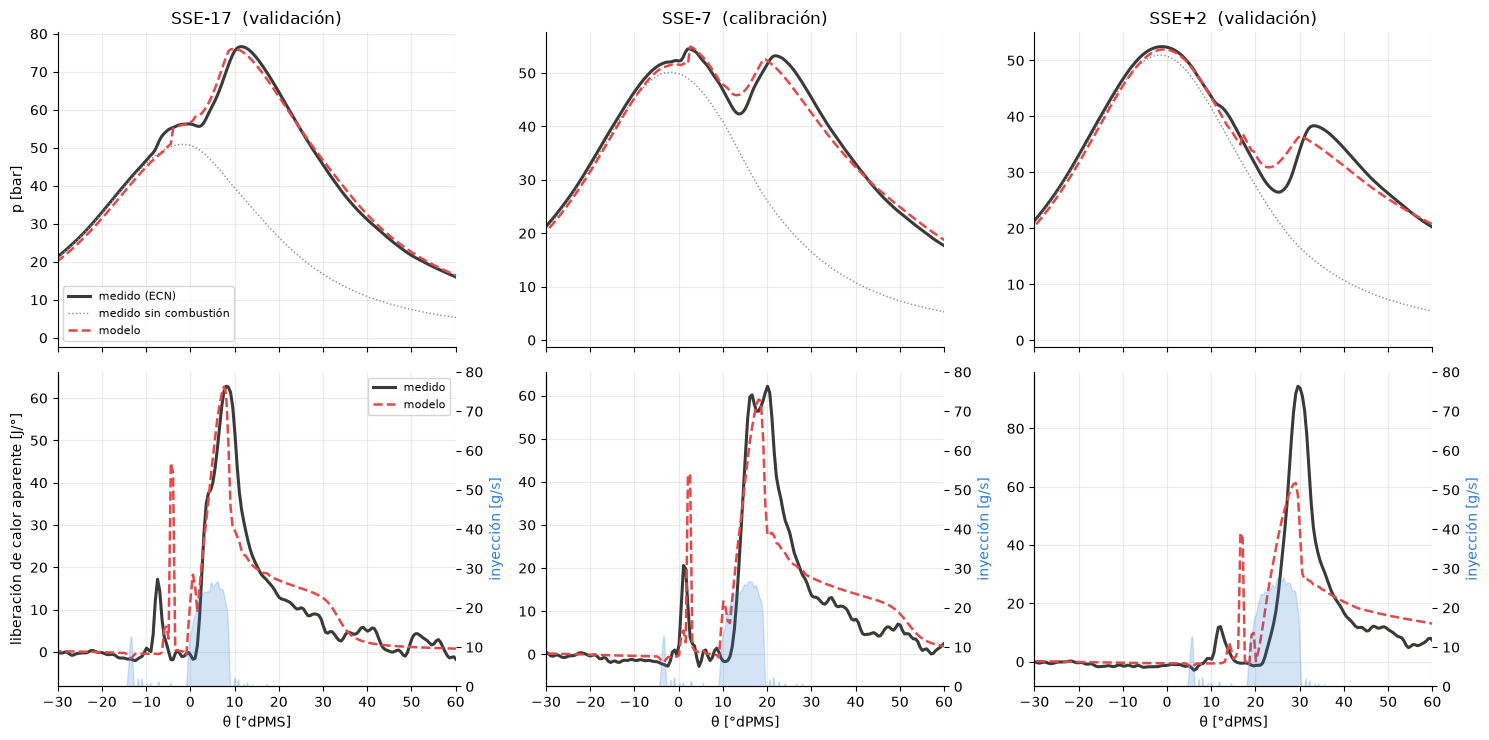

caso    pmax mod pmax exp  err % rms bar |       AHRR mod       AHRR exp | IMEPg mod    exp
SSE-17      76.0     76.6   -0.8    1.75 |  62.7 J/° @  7.6  62.8 J/° @  8.1 |      9.36   8.61
SSE-7       55.0     54.5    0.8    1.68 |  59.1 J/° @ 18.1  62.1 J/° @ 20.1 |      9.12   8.55
SSE+2       52.0     52.5   -0.9    2.09 |  61.3 J/° @ 29.1  94.5 J/° @ 29.6 |      9.15   8.47


In [16]:
# FIGURA DE VALIDACIÓN: presión y liberación de calor aparente, modelo vs. ECN (mismo método para ambos)
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
filas = []
for k, caso in enumerate(["SSE-17", "SSE-7", "SSE+2"]):
    o = CASOS[caso]; c = ECN["casos"][caso]
    cad = o["cad"]; pe = np.interp(cad, c["cad"], c["p_kPa"])*1e3; V = volumen(cad, o["Vc"])
    hm, he = aparente(cad, o["p"], V), aparente(cad, pe, V)
    ax[0, k].plot(c["cad"], np.array(c["p_kPa"])/100, color=COL["tinta"], lw=2.2, label="medido (ECN)")
    ax[0, k].plot(c["cad"], np.array(c["p_motor_kPa"])/100, color=COL["gris"], lw=1, ls=":", label="medido sin combustión")
    ax[0, k].plot(cad, o["p"]/1e5, color=COL["aviso"], lw=1.8, ls="--", label="modelo")
    ax[0, k].set_xlim(-30, 60); ax[0, k].set_title(f"{caso}" + ("  (calibración)" if caso == "SSE-7" else "  (validación)"))
    ax[1, k].plot(cad, he, color=COL["tinta"], lw=2.2, label="medido"); ax[1, k].plot(cad, hm, color=COL["aviso"], lw=1.8, ls="--", label="modelo")
    ca_i, m_i = perfil_inyeccion(caso); ax1b = ax[1, k].twinx(); ax1b.fill_between(ca_i, m_i*1e3, color=COL["fuel"], alpha=0.2); ax1b.set_ylim(0, 80); ax1b.grid(False)
    ax1b.set_ylabel("inyección [g/s]", color=COL["fuel"]); ax[1, k].set_xlabel("θ [°dPMS]")
    m = (cad > -30) & (cad < 60)
    filas.append((caso, o["p"][m].max()/1e5, pe[m].max()/1e5, np.sqrt(np.mean((o["p"][m] - pe[m])**2))/1e5,
                  hm[m].max(), cad[m][np.argmax(hm[m])], he[m].max(), cad[m][np.argmax(he[m])],
                  o["imep_g"]/1e5, np.trapezoid(pe, V)/o["Vd"]/1e5))
ax[0, 0].set_ylabel("p [bar]"); ax[1, 0].set_ylabel("liberación de calor aparente [J/°]"); ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'caso':7s} {'pmax mod':>8s} {'pmax exp':>8s} {'err %':>6s} {'rms bar':>7s} | {'AHRR mod':>14s} {'AHRR exp':>14s} | {'IMEPg mod':>9s} {'exp':>6s}")
for f in filas:
    print(f"{f[0]:7s} {f[1]:8.1f} {f[2]:8.1f} {100*(f[1]-f[2])/f[2]:6.1f} {f[3]:7.2f} | {f[4]:5.1f} J/° @{f[5]:5.1f} {f[6]:5.1f} J/° @{f[7]:5.1f} | {f[8]:9.2f} {f[9]:6.2f}")

**Lectura de la validación.**
- **Presión pico.** El modelo la predice dentro del 1 % en los **tres** casos, aunque solo uno se usó para calibrar.
- **Liberación de calor.** Reproduce la diferencia física entre los avances:
  - con la principal cerca del PMS (SSE−17), la presión sube por combustión antes de que el pistón baje;
  - con la principal tardía (SSE+2), la combustión ocurre ya en expansión y la presión pico es la de compresión.
- **Dónde falla, y por qué es instructivo:**
  - *Pico premezclado de SSE+2.* El modelo lo subestima. En una zona de chorro homogénea toda la mezcla tiene el mismo $\phi$ medio, cuando en el chorro real coexisten mezclas ricas que encienden antes. Es el límite de cualquier modelo 0D.
  - *Pico del piloto.* El modelo lo muestra como un "soplo" premezclado de ~45 J/°, más alto y más angosto que el medido. Toda la zona piloto enciende a la vez, mientras que en el chorro real parte del piloto queda demasiado pobre y quema lento o incompleto.
  - *IMEP.* El modelo da un 7-9 % más. En el motor óptico la liberación de calor medida suma solo el 91 % de la energía del combustible: hay *blow-by* por los anillos y combustión incompleta cerca de la ventana de cuarzo, y el modelo no incluye ninguno de los dos.

## 7. Emisiones: el compromiso NOx-hollín

**NO térmico (Zeldovich).** El NO se forma en los gases quemados **cerca de $\phi=1$** que rodean la llama de difusión, donde la temperatura es la de llama adiabática estequiométrica $T_{ad}$ (no la temperatura media). Cada paso de combustión crea un "paquete" de productos a $T_{ad}$ del ambiente actual, que luego sigue la presión isentrópicamente:

$$\frac{d[NO]}{dt}=2k_1[O]_e[N_2],\qquad k_1=7.6\times10^{13}e^{-38000/T},\qquad [O]_e=\frac{397}{\sqrt T}[O_2]_e^{1/2}e^{-31090/T}\ \ (\text{mol/cm}^3)$$

**Hollín (Hiroyasu, dos pasos).** Se forma del vapor de combustible y de sus precursores (C₂H₂) en la zona rica, y se oxida con O₂ en caliente:

$$\frac{dm_{sf}}{dt}=A_f\,m_{fv}\,p^{0.5}e^{-E_f/RT},\qquad \frac{dm_{so}}{dt}=A_o\,m_s\,x_{O_2}\,p^{1.8}e^{-E_o/RT}$$

El NO calculado es una estimación de orden de magnitud: sin dilución de los paquetes, sobreestima. El hollín **no se calibró** (no hay medición de humo en este conjunto de datos), así que se reporta **relativo al caso base**. Lo que el modelo sí captura con confianza son las **tendencias**.

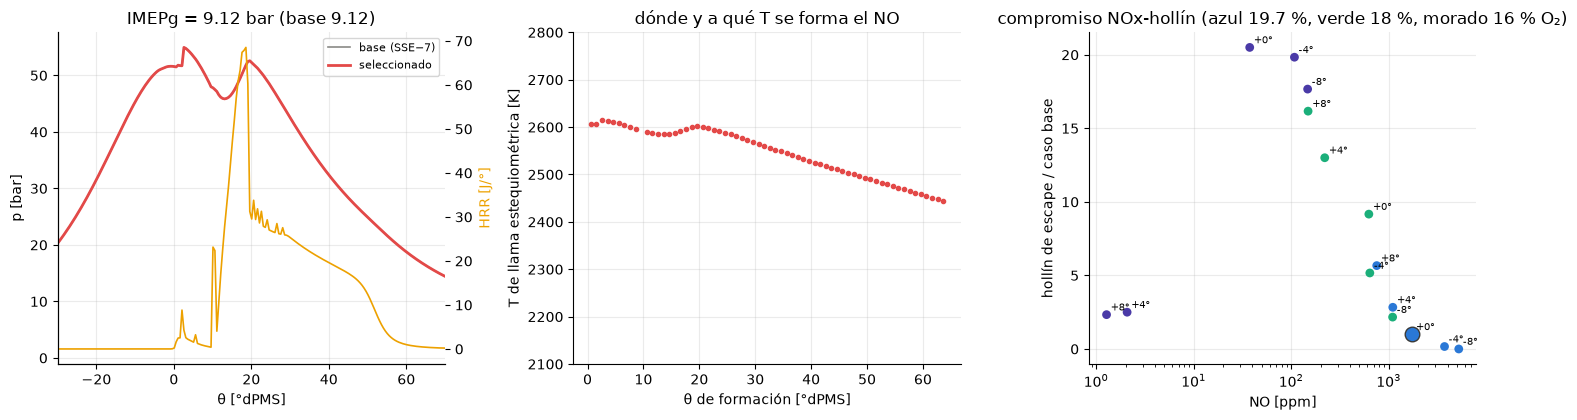

NO = 1722 ppm (base 1722); hollín = 1.00 x base; oxidado: 97 % de lo formado


Output()

In [17]:
# WIDGET 5 — inyección: avance y EGR -> presión, llama y el compromiso NOx-hollín
MALLA = RES["malla"]; BASE = MALLA["0|0.197"]
def widget_emisiones(avance=0, o2=0.197):
    r = MALLA[f"{avance}|{o2}"]; s0 = BASE["hollin_kg"][-1] if hasattr(BASE["hollin_kg"], "__len__") else BASE["hollin_kg"]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
    ax[0].plot(BASE["cad"], BASE["p"]/1e5, color=COL["gris"], lw=1.2, label="base (SSE−7)")
    ax[0].plot(r["cad"], r["p"]/1e5, color=COL["aviso"], lw=2, label="seleccionado"); ax[0].set_xlim(-30, 70)
    ax[0].set_xlabel("θ [°dPMS]"); ax[0].set_ylabel("p [bar]"); ax[0].legend(fontsize=8)
    ax0b = ax[0].twinx(); ax0b.plot(r["cad"], r["hrr"], color=COL["NO"], lw=1.2); ax0b.set_ylabel("HRR [J/°]", color=COL["NO"]); ax0b.grid(False)
    ax[0].set_title(f"IMEPg = {r['imep_g']/1e5:.2f} bar (base {BASE['imep_g']/1e5:.2f})")
    if len(r["T_llama"]): ax[1].plot(r["cad_llama"], r["T_llama"], "o", ms=3, color=COL["aviso"])
    ax[1].set_xlabel("θ de formación [°dPMS]"); ax[1].set_ylabel("T de llama estequiométrica [K]")
    ax[1].set_title("dónde y a qué T se forma el NO"); ax[1].set_ylim(2100, 2800)
    for k, v in MALLA.items():
        sh, oo = k.split("|"); sel = (int(sh) == avance and float(oo) == o2)
        ax[2].scatter(v["NO_ppm"], v["hollin_kg"][-1]/s0 if s0 > 0 else 0, s=110 if sel else 40,
                      color={"0.197": COL["manivela"], "0.18": COL["control"], "0.16": COL["CH2O"]}[oo],
                      edgecolor=COL["tinta"] if sel else "none", zorder=3 if sel else 2)
        ax[2].annotate(f"{int(sh):+d}°", (v["NO_ppm"], v["hollin_kg"][-1]/s0 if s0 > 0 else 0), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[2].set_xscale("log"); ax[2].set_xlabel("NO [ppm]"); ax[2].set_ylabel("hollín de escape / caso base")
    ax[2].set_title("compromiso NOx-hollín (azul 19.7 %, verde 18 %, morado 16 % O₂)")
    plt.tight_layout(); plt.show()
    print(f"NO = {r['NO_ppm']:.0f} ppm (base {BASE['NO_ppm']:.0f}); hollín = {r['hollin_kg'][-1]/s0:.2f} x base; "
          f"oxidado: {100*(1 - r['hollin_kg'][-1]/max(r['hollin_formado_kg'][-1], 1e-30)):.0f} % de lo formado")

display(interactive_output(widget_emisiones, {
    "avance": SelectionSlider(options=[-8, -4, 0, 4, 8], value=0, description="Δ inyección [°]"),
    "o2": ToggleButtons(options=[("19.7 % O₂ (sin EGR)", 0.197), ("18 % (EGR)", 0.18), ("16 % (EGR alto)", 0.16)], description="admisión")}))

**Lectura.**
- **Adelantar la inyección (Δ < 0).** La combustión ocurre más cerca del PMS: presión y temperatura de llama suben, el **NO se dispara** y el hollín, que se oxida en caliente, baja.
- **Retrasarla.** Hace lo contrario y además pierde trabajo (IMEP menor).
- **La recirculación de gases (EGR).** Diluye el O₂ de admisión, **baja $T_{ad}$** unos 100-250 K y el NO cae casi exponencialmente, pero entonces se oxida menos hollín.

Ninguna palanca de la combustión baja los dos a la vez. Por eso los diésel modernos necesitan **post-tratamiento**: SCR con urea para el NOx y filtro de partículas (DPF) para el hollín.

## 8. Dinámica del mecanismo: de la presión al par

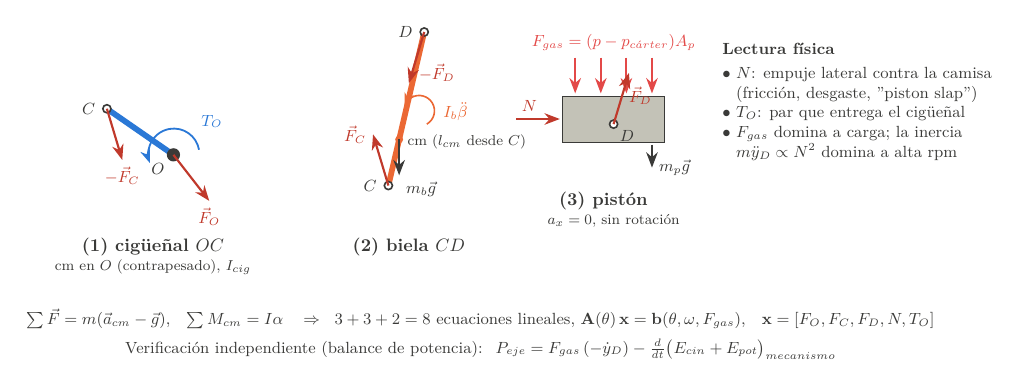

Con ω constante (cuasi-estático, verificado en §11), cada ángulo da un sistema lineal $\mathbf A(\theta)\mathbf x=\mathbf b(\theta,\omega,F_{gas})$ de **8 ecuaciones**: equilibrio de fuerzas y momentos del cigüeñal (contrapesado), de la biela (con su inercia $I_b\ddot\beta$) y del pistón (sin rotación ni aceleración lateral). La verificación independiente es el **balance de potencia**: la potencia que el gas entrega al pistón, menos la que se acumula como energía cinética y potencial del mecanismo, debe salir por el cigüeñal.

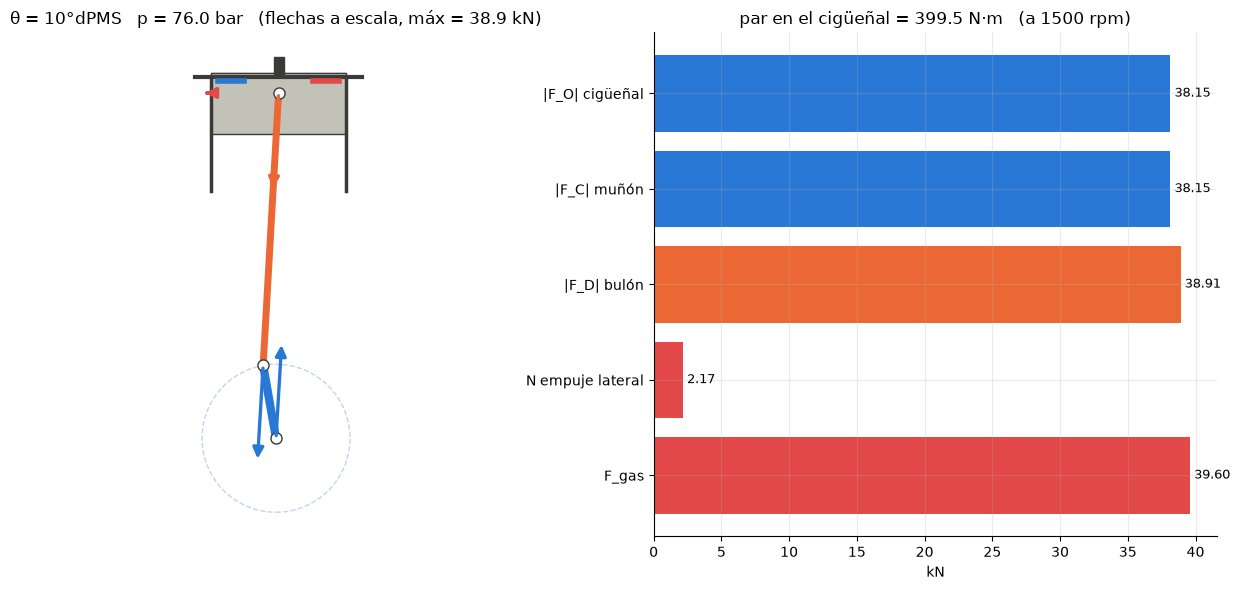

Output()

In [18]:
# WIDGET 6 — DCL vivo: fuerzas reales en el mecanismo en cualquier ángulo, separando gas e inercia
def dibujar_mecanismo(ax, th, T_gas=None, iny=False, valvulas=(False, False), escala=1.0):
    k = cinematica(np.array([th])); b = k["b"][0]; y = k["y"][0]
    C_ = (-R_OC*np.sin(th), R_OC*np.cos(th)); D_ = (EOFF, y)
    yc = Y_PMS + VC/A_P; xL, xR = EOFF - BORE/2, EOFF + BORE/2
    ax.add_patch(Circle((0, 0), R_OC, fill=False, ls="--", color=COL["manivela"], alpha=0.3))
    if T_gas is not None and np.isfinite(T_gas):
        cm = plt.cm.inferno((min(max(T_gas, 300), 2400) - 300)/2100*0.85 + 0.1)
        ax.add_patch(Rectangle((xL, y + 0.012), BORE, yc - y - 0.012, color=cm, alpha=0.75))
    ax.add_patch(Rectangle((xL, y - 0.025), BORE, 0.037, color=COL["metal"], ec=COL["tinta"]))
    ax.plot([xL, xL], [y - 0.06, yc + 0.003], color=COL["tinta"], lw=2.5); ax.plot([xR, xR], [y - 0.06, yc + 0.003], color=COL["tinta"], lw=2.5)
    ax.plot([xL - 0.01, xR + 0.01], [yc + 0.003, yc + 0.003], color=COL["tinta"], lw=3)
    ax.add_patch(Rectangle((EOFF - 0.003, yc + 0.003), 0.006, 0.012, color=COL["tinta"]))
    if iny:
        for s in (-1, 1):
            ax.plot([EOFF, EOFF + s*0.03], [yc, yc - 0.008], color=COL["fuel"], lw=3, alpha=0.8)
    for (abierta, x0, cc) in [(valvulas[0], xL + 0.012, COL["frio"]), (valvulas[1], xR - 0.012, COL["caliente"])]:
        dy = 0.006 if abierta else 0.0
        ax.plot([x0 - 0.008, x0 + 0.008], [yc - dy, yc - dy], color=cc, lw=4)
    ax.plot([0, C_[0]], [0, C_[1]], color=COL["manivela"], lw=6, solid_capstyle="round")
    ax.plot([C_[0], D_[0]], [C_[1], D_[1]], color=COL["biela"], lw=5, solid_capstyle="round")
    for P in [(0, 0), C_, D_]: ax.plot(*P, "o", ms=8, mfc="white", mec=COL["tinta"])
    ax.set_aspect("equal"); ax.set_xlim(-0.11, 0.11); ax.set_ylim(-0.06, yc + 0.03); ax.axis("off")
    return dict(O=(0, 0), C=C_, D=D_)

def widget_dcl(caso="SSE-17", cad_sel=10.0, rpm=1500, gas=True, inercia=True):
    c = C720[caso]; j = int(np.argmin(np.abs(c["cad"] - cad_sel))); w = 2*np.pi*rpm/60
    Fg = (c["p"][j] - P_CARTER)*A_P if gas else 0.0
    masas = MASAS if inercia else dict(P=0.0, B=0.0); Ib = I_B if inercia else 0.0
    X, k = newton_euler(np.radians(c["cad"][j]), w, Fg, masas, Ib); x = X[0]
    F = {"O": x[0:2], "C": x[2:4], "D": x[4:6]}
    fig, (ax, axt) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.1, 1]})
    P = dibujar_mecanismo(ax, np.radians(c["cad"][j]), T_gas=c["T"][j])
    Fmax = max(np.linalg.norm(v) for v in F.values()) + 1e-9; esc = 0.06/Fmax
    for pt, v, cc in [("O", F["O"], COL["manivela"]), ("C", -F["C"], COL["manivela"]), ("D", -F["D"], COL["biela"])]:
        ax.annotate("", xy=(P[pt][0] + v[0]*esc, P[pt][1] + v[1]*esc), xytext=P[pt],
                    arrowprops=dict(arrowstyle="-|>", color=cc, lw=2.4, mutation_scale=16))
    ax.annotate("", xy=(P["D"][0] - 0.045, P["D"][1]), xytext=(P["D"][0] - 0.045 - x[6]*esc, P["D"][1]),
                arrowprops=dict(arrowstyle="-|>", color=COL["aviso"], lw=2.4, mutation_scale=16))
    ax.set_title(f"θ = {c['cad'][j]:.0f}°dPMS   p = {c['p'][j]/1e5:.1f} bar   (flechas a escala, máx = {Fmax/1e3:.1f} kN)")
    nombres = ["|F_O| cigüeñal", "|F_C| muñón", "|F_D| bulón", "N empuje lateral", "F_gas"]
    vals = [np.linalg.norm(F["O"])/1e3, np.linalg.norm(F["C"])/1e3, np.linalg.norm(F["D"])/1e3, abs(x[6])/1e3, abs(Fg)/1e3]
    axt.barh(nombres[::-1], vals[::-1], color=[COL["aviso"], COL["aviso"], COL["biela"], COL["manivela"], COL["manivela"]])
    for yy, vv in enumerate(vals[::-1]): axt.text(vv, yy, f" {vv:.2f}", va="center", fontsize=9)
    axt.set_xlabel("kN"); axt.set_title(f"par en el cigüeñal = {-x[7]:.1f} N·m   (a {rpm} rpm)")
    plt.tight_layout(); plt.show()

display(interactive_output(widget_dcl, {
    "caso": Dropdown(options=list(C720), value="SSE-17", description="caso"),
    "cad_sel": FloatSlider(10, min=-360, max=359, step=1, description="θ [°dPMS]"),
    "rpm": IntSlider(1500, min=800, max=4500, step=100, description="rpm (inercia)"),
    "gas": Checkbox(True, description="fuerza del gas"), "inercia": Checkbox(True, description="inercia")}))

**Lectura.** Cerca del PMS de combustión la **fuerza del gas** domina: ~25 kN sobre el muñón a 76 bar. Prueba a apagar el gas en el PMS de escape (θ = ±360°): solo queda la inercia, que **tira** de la biela (tracción) y crece con $\omega^2$. A 4500 rpm se acerca a la magnitud de la fuerza del gas. El **empuje lateral** $N$ cambia de signo al pasar el PMS: es el golpe del pistón contra la camisa, y el descentrado $e$ se elige para que ese cambio ocurra a presión baja.

## 9. El motor completo, carrera por carrera

Se ensambla el ciclo de 720°. La admisión y el escape se toman a presión constante (las del ensayo: 151 y 146 kPa) y las válvulas se cierran y abren en los ángulos medidos. El ciclo cerrado es el modelo validado de §6. El panel de la derecha cambia según la carrera, para mostrar en cada una la física que la gobierna:
- **Admisión.** La cadena turbo → intercooler → cilindro.
- **Compresión.** El "reloj químico" de Livengood-Wu, $I(t)=\int_{IVC}^{t}dt'/\tau_{ig}(T,p)$: el autoencendido llega cuando $I\to1$.
- **Combustión-expansión.** Las zonas de chorro: $\phi$, temperatura, CH₂O, OH, NO y hollín.
- **Escape.** La entalpía que se lleva el gas y lo que de ella puede recuperar la turbina.

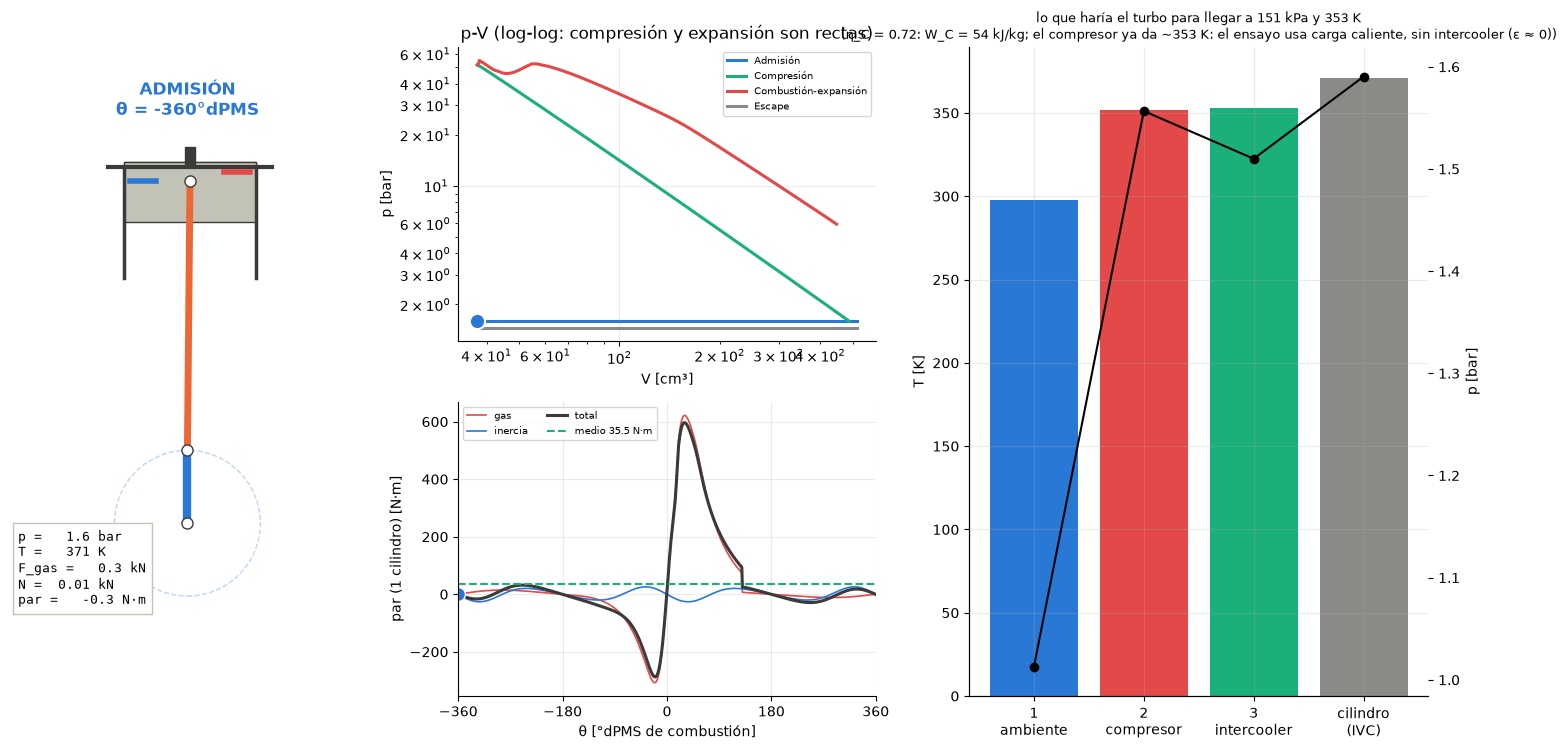

In [19]:
# Tabla tau(T, p) para el reloj químico de Livengood-Wu (phi = 1, aire del ensayo)
_TT = np.arange(700, 1101, 50.0); _PP = np.array([20e5, 40e5, 60e5])
_TAU = np.array([[tau_ignicion(T, p, 1.0, X=X_ECN) for T in _TT] for p in _PP])
def tau_tabla(T, p):
    lt = np.array([np.interp(T, _TT, np.log(_TAU[i])) for i in range(len(_PP))])
    return float(np.exp(np.interp(p, _PP, lt)))

NOMBRES_CARR = list(CARRERAS)
def widget_motor(caso, carrera, i):
    c = C720[caso]; o = CASOS[caso]
    rangos = {"Ciclo completo": (-360, 360), "Admisión": (-360, IVC), "Compresión": (IVC, 0), "Combustión-expansión": (0, EVO), "Escape": (EVO, 360)}
    a, b = rangos[carrera]; sel = np.where((c["cad"] >= a) & (c["cad"] < b))[0]; j = sel[int(i/100*(len(sel) - 1))]
    cad = c["cad"][j]; ic = int(c["carrera"][j]); nom = NOMBRES_CARR[ic]
    ca_i, m_i = perfil_inyeccion(caso); iny = np.interp(cad, ca_i, m_i, left=0, right=0) > 1e-3
    fig = plt.figure(figsize=(15, 7.6)); gs = fig.add_gridspec(2, 3, width_ratios=[0.85, 1, 1.1])
    ax0 = fig.add_subplot(gs[:, 0])
    dibujar_mecanismo(ax0, np.radians(cad), T_gas=c["T"][j], iny=iny, valvulas=(ic == 0, ic == 3))
    ax0.set_title(f"{nom.upper()}\nθ = {cad:.0f}°dPMS", color=CARRERAS[nom], fontsize=12, fontweight="bold")
    ax0.text(-0.105, -0.05, f"p = {c['p'][j]/1e5:5.1f} bar\nT = {c['T'][j]:5.0f} K\nF_gas = {(c['p'][j] - P_CARTER)*A_P/1e3:5.1f} kN\n"
             f"N = {c['X'][j, 6]/1e3:5.2f} kN\npar = {c['par'][j]:6.1f} N·m", fontsize=9, family="monospace",
             bbox=dict(fc="white", ec=COL["metal"]))
    ax1 = fig.add_subplot(gs[0, 1])
    for kc, (nm, cc) in enumerate(CARRERAS.items()):
        m = c["carrera"] == kc; alfa = 1.0 if carrera in ("Ciclo completo", nm) else 0.15
        ax1.plot(c["V"][m]*1e6, c["p"][m]/1e5, color=cc, lw=2.2, alpha=alfa, label=nm)
    ax1.plot(c["V"][j]*1e6, c["p"][j]/1e5, "o", ms=11, color=CARRERAS[nom], mec="white", mew=1.5)
    ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_xlabel("V [cm³]"); ax1.set_ylabel("p [bar]"); ax1.legend(fontsize=7)
    ax1.set_title("p-V (log-log: compresión y expansión son rectas)")
    ax2 = fig.add_subplot(gs[1, 1])
    ax2.plot(c["cad"], c["par_gas"], color=COL["O2"], lw=1.2, label="gas"); ax2.plot(c["cad"], c["par_inercia"], color=COL["fuel"], lw=1.2, label="inercia")
    ax2.plot(c["cad"], c["par"], color=COL["tinta"], lw=2.2, label="total"); ax2.axhline(np.mean(c["par"]), color=COL["control"], ls="--", label=f"medio {np.mean(c['par']):.1f} N·m")
    ax2.plot(cad, c["par"][j], "o", ms=10, color=CARRERAS[nom], mec="white"); ax2.set_xlim(-360, 360); ax2.set_xticks(np.arange(-360, 361, 180))
    ax2.set_xlabel("θ [°dPMS de combustión]"); ax2.set_ylabel("par (1 cilindro) [N·m]"); ax2.legend(fontsize=7, ncol=2)
    ax3 = fig.add_subplot(gs[:, 2])
    if ic == 0:                       # admisión: la cadena turbo -> intercooler -> cilindro
        PI = OP["p_int"]/1.013e5/0.97; T2, wc = compresor(1.013e5, 298.0, PI, 0.72); T3 = OP["T_int"]
        est = ["1\nambiente", "2\ncompresor", "3\nintercooler", "cilindro\n(IVC)"]
        ax3.bar(est, [298, T2, T3, o["T_ivc"]], color=[COL["frio"], COL["caliente"], COL["control"], COL["gris"]])
        ax3.set_ylabel("T [K]"); a3 = ax3.twinx(); a3.plot(est, [1.013, PI*1.013, OP["p_int"]/1e5, o["p_ivc"]/1e5], "ko-"); a3.set_ylabel("p [bar]"); a3.grid(False)
        eps_ic = (T2 - T3)/(T2 - 298)
        txt_ic = f"ε_IC = {eps_ic:.2f}" if eps_ic > 0.05 else "el compresor ya da ~353 K: el ensayo usa carga caliente, sin intercooler (ε ≈ 0)"
        ax3.set_title(f"lo que haría el turbo para llegar a 151 kPa y 353 K\n(η_C = 0.72: W_C = {wc/1e3:.0f} kJ/kg; {txt_ic})", fontsize=9)
    elif ic == 1:                     # compresión: reloj químico de Livengood-Wu
        m = (o["cad"] >= IVC) & (o["cad"] <= cad)
        I = np.cumsum([np.radians(0.5)/(2*np.pi*o["rpm"]/60)/tau_tabla(T, p) for T, p in zip(o["TA"][m], o["p"][m])]) if m.sum() else np.array([0])
        mm = (o["cad"] >= IVC) & (o["cad"] <= 10)
        I_all = np.cumsum([np.radians(0.5)/(2*np.pi*o["rpm"]/60)/tau_tabla(T, p) for T, p in zip(o["TA"][mm], o["p"][mm])])
        ax3.plot(o["cad"][mm], I_all, color=COL["gris"], lw=1.2); ax3.plot(o["cad"][m], I, color=COL["control"], lw=3)
        ax3.axhline(1.0, color=COL["aviso"], ls="--"); ax3.set_ylim(0, 1.3); ax3.set_xlabel("θ [°dPMS]"); ax3.set_ylabel("I = ∫ dt / τ_ig(T, p)")
        a3 = ax3.twinx(); a3.plot(o["cad"][mm], o["TA"][mm], color=COL["aviso"], lw=1); a3.set_ylabel("T del aire [K]"); a3.grid(False)
        ax3.set_title(f"reloj químico del AIRE (si fuera mezcla φ=1): I = {I[-1]:.3f}\n"
                      "el aire solo NO llega a 1: hace falta inyectar en el PMS")
    elif ic == 2:                     # combustión: las zonas de chorro
        Zs = o["zonas"]; nz = len(Zs["T"]); mm = (o["cad"] > o["eventos"][0][0] - 2) & (o["cad"] < 60)
        for z in range(nz):
            ls = "-" if z == nz - 1 else ":"
            ax3.plot(o["cad"][mm], Zs["T"][z][mm], color=COL["aviso"], ls=ls, lw=2, label=["T piloto", "T principal"][min(z, 1)])
        ax3.plot(o["cad"][mm], o["TA"][mm], color=COL["gris"], lw=1.5, label="T aire")
        ax3.axvline(cad, color=CARRERAS[nom]); ax3.set_ylabel("T [K]"); ax3.set_xlabel("θ [°dPMS]"); ax3.legend(fontsize=7, loc="upper left")
        a3 = ax3.twinx()
        for z in range(nz):
            ls = "-" if z == nz - 1 else ":"
            a3.semilogy(o["cad"][mm], np.maximum(Zs["YCH2O"][z][mm], 1e-8), color=COL["CH2O"], ls=ls)
            a3.semilogy(o["cad"][mm], np.maximum(Zs["YOH"][z][mm], 1e-8), color=COL["OH"], ls=ls)
        a3.set_ylim(1e-7, 1e-1); a3.set_ylabel("Y (morado CH₂O, naranja OH)"); a3.grid(False)
        kk = int(np.argmin(np.abs(o["cad"] - cad)))
        txt_phi = ", ".join("%.2f" % Zs["phi"][z][kk] for z in range(nz))
        ax3.set_title(f"zonas de chorro (piloto, principal): φ = {txt_phi}\n"
                      f"NO = {o['NO_kg'][kk]*1e6:.2f} mg, hollín = {o['hollin_kg'][kk]*1e9:.0f} µg")
    else:                             # escape
        T_evo = o["TA"][-1]; m_tot = o["m_aire"] + o["m_iny"]
        cp_ex = 1150.0; H = m_tot*cp_ex*(T_evo - 298); Wt = m_tot*cp_ex*T_evo*(1 - (1.013e5/OP["p_exh"])**(0.33/1.33))*0.70
        Q_comb = o["m_iny"]*44.6e6
        partes = {"trabajo indicado": o["W"], "pérdida a paredes": o["Qw"][-1], "entalpía de escape": H,
                  "(recuperable en turbina)": Wt}
        ax3.barh(list(partes)[::-1], [v/Q_comb*100 for v in list(partes.values())[::-1]],
                 color=[COL["control"], COL["aviso"], COL["gris"], COL["manivela"]][::-1])
        ax3.set_xlabel("% de la energía del combustible"); ax3.set_title(f"balance del ciclo: T_EVO = {T_evo:.0f} K")
    plt.tight_layout(); plt.show()

caso_dd = Dropdown(options=list(C720), value="SSE-7", description="caso ECN")
carr_tb = ToggleButtons(options=["Ciclo completo"] + NOMBRES_CARR, description="carrera")
play = Play(value=0, min=0, max=100, step=2, interval=200); avance = IntSlider(0, min=0, max=100, description="avance %")
jslink((play, "value"), (avance, "value"))
display(VBox([HBox([caso_dd, carr_tb]), HBox([play, avance]),
              interactive_output(widget_motor, {"caso": caso_dd, "carrera": carr_tb, "i": avance})]))

### Lectura física, carrera por carrera
- **Admisión.** Con turbo, $p_{adm}$ (151 kPa) es mayor que $p_{esc}$ (146 kPa): el gas **empuja** al pistón y hasta el bombeo da par positivo. El compresor calienta el aire a ~350 K y el intercooler lo devuelve cerca de la temperatura ambiente. En este motor de laboratorio, un acondicionador externo hace el papel de los dos.
- **Compresión.** El par es negativo: el volante y los otros cilindros pagan la compresión. El reloj químico muestra lo esencial del diésel: el **aire solo** no llega a autoencenderse en el tiempo disponible. Es el combustible inyectado, al formar mezcla rica caliente, lo que "pone en marcha" la química.
- **Combustión-expansión.** El piloto enciende en dos etapas (CH₂O y luego OH). El chorro principal arrastra los productos calientes del piloto y enciende casi sin retardo: para eso existe el piloto, para suavizar el pico de presión y el ruido. Mientras se inyecta, la principal quema al ritmo del arrastre de aire, es decir, **controlada por mezcla**.
- **Escape.** Cerca de un tercio de la energía sale como entalpía del gas. Una parte, del orden de un 5-10 % de la energía del combustible, la recupera la turbina, y es justamente la que paga la compresión de la admisión.

## 10. Del cilindro al motor: acoplamiento del turbo y curva de potencia

El ensayo del ECN es un único punto de operación. Para obtener la **curva de par y potencia** se usa el mismo modelo validado en un motor **metálico de 4 cilindros con la geometría ECN** (1.91 L, $r_c$ geométrica 15.8: sin las pérdidas del pistón óptico) y una estrategia de ECU explícita:

- **Límite de humo.** El combustible inyectado es $m_f=m_a/(\lambda_{humo}AF_{st})$ con $\lambda_{humo}=1.45$. Es el par máximo sin humo visible.
- **Mapa de presión de admisión.** Objetivo de 2.3 bar, que el **turbo debe poder pagar**. Con $\dot W_C(\Pi_C)$ y la entalpía de escape del propio ciclo se resuelve $p_5$ de $\eta_m\dot W_T=\dot W_C$. Si $p_5$ supera 2.8 bar (turbina de geometría variable cerrada), se reduce la presión de admisión: es el **retardo del turbo a bajas rpm**.
- **Inyección.** Presión de riel de 800 a 1800 bar con las rpm, piloto de 1.4 mg a 1.28 ms del principal, y avance creciente con las rpm. Si $p_{max}>160$ bar, se retrasa la inyección.
- **Freno.** $\text{BMEP}=\text{IMEP}_g-\text{PMEP}-\text{FMEP}$, con $\text{PMEP}=p_5-p_{adm}$ y $\text{FMEP}=0.97+0.15N+0.05N^2$ bar ($N$ en miles de rpm; Heywood).

**Comparación (no ajuste):** el motor de producción GM/Fiat 1.9 CDTi (Z19DTH) tiene el mismo diámetro y carrera, $r_c$ = 17.5, 110 kW a 4000 rpm y 320 N·m entre 2000 y 2750 rpm.

In [20]:
# Estrategia de ECU, inyección sintética y acoplamiento turbo-cilindro
def _cd_efectivo():
    ca, m = perfil_inyeccion("SSE-7"); ev = agrupar_eventos(ca, m, 9000.0); a, b = ev[-1]
    sel = (ca > a + 1.5) & (ca < b - 1.5); A_h = G["n_holes"]*math.pi/4*G["d_hole"]**2
    return float(np.mean(m[sel])/(A_h*math.sqrt(2*RHO_F*(800e5 - 50e5))))
CD_INY = _cd_efectivo()      # coeficiente de descarga efectivo, de la tasa medida a 800 bar

def perfil_sintetico(rpm, m_pil, m_main, soi_main, dwell_ms=1.28, p_rail=800e5, p_cil=60e5, rampa=0.12e-3):
    wdeg = 6.0*rpm; A_h = G["n_holes"]*math.pi/4*G["d_hole"]**2
    mmax = CD_INY*A_h*math.sqrt(2*RHO_F*max(p_rail - p_cil, 1e6))
    def pulso(m, soi):
        dur = m/mmax + rampa
        if dur < 2*rampa:
            dur = 2*math.sqrt(m*rampa/mmax); return [soi, soi + dur/2*wdeg, soi + dur*wdeg], [0, m/(dur/2), 0]
        return [soi, soi + rampa*wdeg, soi + (dur - rampa)*wdeg, soi + dur*wdeg], [0, mmax, mmax, 0]
    soi_pil = soi_main - dwell_ms*1e-3*wdeg
    c1, r1 = pulso(m_pil, soi_pil); c2, r2 = pulso(m_main, soi_main)
    ca = np.array([soi_pil - 1] + c1 + c2 + [c2[-1] + 1]); mm = np.array([0] + r1 + r2 + [0])
    ca_f = np.arange(ca[0], ca[-1], 0.05); return ca_f, np.interp(ca_f, ca, mm)

ECU = dict(lam_humo=1.45, p_int_max=2.3e5, p5_max=2.8e5, pmax_lim=160e5, eta_C=0.72, eta_T=0.70, eta_m=0.95,
           eps_IC=0.75, dp_IC=0.03, p_amb=1.0e5, T_amb=298.0, dT_ivc=18.0, n_cil=4)
fmep = lambda rpm: (0.97 + 0.15*rpm/1000 + 0.05*(rpm/1000)**2)*1e5
p_rail = lambda rpm: min(800e5 + 400e5*(rpm - 1000)/1000, 1800e5)
soi_main = lambda rpm: -2.0 - 2.0*(rpm - 1500)/1000

def admision(p_int, E=ECU):
    PI = p_int/(E["p_amb"]*(1 - E["dp_IC"])); T2, wc = compresor(E["p_amb"], E["T_amb"], PI, E["eta_C"])
    return PI, T2, T2 - E["eps_IC"]*(T2 - E["T_amb"]), wc

def punto(rpm, p_int, retraso=0.0, E=ECU):
    PI, T2, T3, wc = admision(p_int, E); T_ivc = T3 + E["dT_ivc"]
    g = ct.Solution(MECH); g.TPX = T_ivc, p_int, X_AIRE; m_air = g.density*volumen(IVC)
    mf = m_air/(E["lam_humo"]*14.7)
    ca, m = perfil_sintetico(rpm, 1.4e-6, mf - 1.4e-6, soi_main(rpm) + retraso, p_rail=p_rail(rpm))
    o = ciclo_diesel("SSE-7", rpm=rpm, p_ivc=p_int, T_ivc=T_ivc, X_aire=X_AIRE, Vc=VC, perfil=(ca, m))
    m_tot = o["m_aire"] + o["m_iny"]; T_evo = o["p"][-1]*o["V"][-1]/(m_tot*290.0)
    mdot_a = E["n_cil"]*m_air*rpm/120; mdot_ex = E["n_cil"]*m_tot*rpm/120; W_C = mdot_a*wc
    falta = lambda p5: turbina_potencia(mdot_ex, T_evo*(p5/o["p"][-1])**(0.33/1.33), p5, E["p_amb"]*1.05, E["eta_T"])*E["eta_m"] - W_C
    try: p5 = brentq(falta, E["p_amb"]*1.06, 8e5)
    except ValueError: p5 = 8e5
    return o, dict(rpm=rpm, p_int=p_int, PI=PI, T2=T2, T3=T3, T_ivc=T_ivc, m_air=m_air, mf=mf, p5=p5,
                   T5=T_evo*(p5/o["p"][-1])**(0.33/1.33), T_evo=T_evo, mdot_a=mdot_a, retraso=retraso)

def desempeno(o, d, E=ECU):
    pmep = d["p5"] - d["p_int"]; bmep = o["imep_g"] - pmep - fmep(d["rpm"])
    par = bmep*E["n_cil"]*o["Vd"]/(4*np.pi); pot = par*2*np.pi*d["rpm"]/60; mdf = E["n_cil"]*d["mf"]*d["rpm"]/120
    return dict(imep=o["imep_g"], pmep=pmep, fmep=fmep(d["rpm"]), bmep=bmep, par=par, pot=pot,
                bsfc=mdf/pot*3.6e9 if pot > 0 else np.nan, eta_b=pot/(mdf*44.6e6), pmax=o["p"].max())

def punto_ecu(rpm, E=ECU):
    p_obj = max(min(E["p_int_max"], 1.0e5 + 1.3e5*(rpm - 1000)/1000), 1.05e5)
    o, d = punto(rpm, p_obj, 0.0, E)
    if d["p5"] > E["p5_max"]:          # la turbina no alcanza: menos presión de admisión
        def exceso(pi):
            PI, T2, T3, wc = admision(pi, E); mda = d["mdot_a"]*(pi/d["p_int"])*(d["T_ivc"]/(T3 + E["dT_ivc"]))
            T5 = d["T_evo"]*(E["p5_max"]/o["p"][-1])**(0.33/1.33)
            return turbina_potencia(mda*(1 + 1/(E["lam_humo"]*14.7)), T5, E["p5_max"], E["p_amb"]*1.05, E["eta_T"])*E["eta_m"] - mda*wc
        try: p_new = brentq(exceso, 1.0e5, p_obj)
        except ValueError: p_new = 1.0e5
        o, d = punto(rpm, max(p_new, 1.0e5), 0.0, E)
    ret = 0.0
    while o["p"].max() > E["pmax_lim"] and ret < 6:
        ret += 3.0; o, d = punto(rpm, d["p_int"], ret, E)
    return o, d, desempeno(o, d, E)

RPMS = [1000, 1500, 2000, 2500, 3000, 3500, 4000]
if RECALCULAR or RES.get("curva") is None:
    t_ini = time.time(); curva = []
    for N in RPMS:
        o, d, r = punto_ecu(N); d.update(r); d.update(cad=o["cad"], p=o["p"], hrr=o["hrr"]); curva.append(d)
        print(f"{N} rpm: par {r['par']:.0f} N·m, {r['pot']/1e3:.1f} kW ({o['cpu']:.0f} s)")
    RES["curva"] = curva; json.dump(_lista(RES), open(ARCH, "w")); RES = _arr(json.load(open(ARCH)))
    print(f"curva calculada en {time.time() - t_ini:.0f} s")
CURVA = RES["curva"]
Z19DTH = dict(P_kW=110.0, rpm_P=4000, par=320.0, rpm_par=(2000, 2750), CR=17.5)

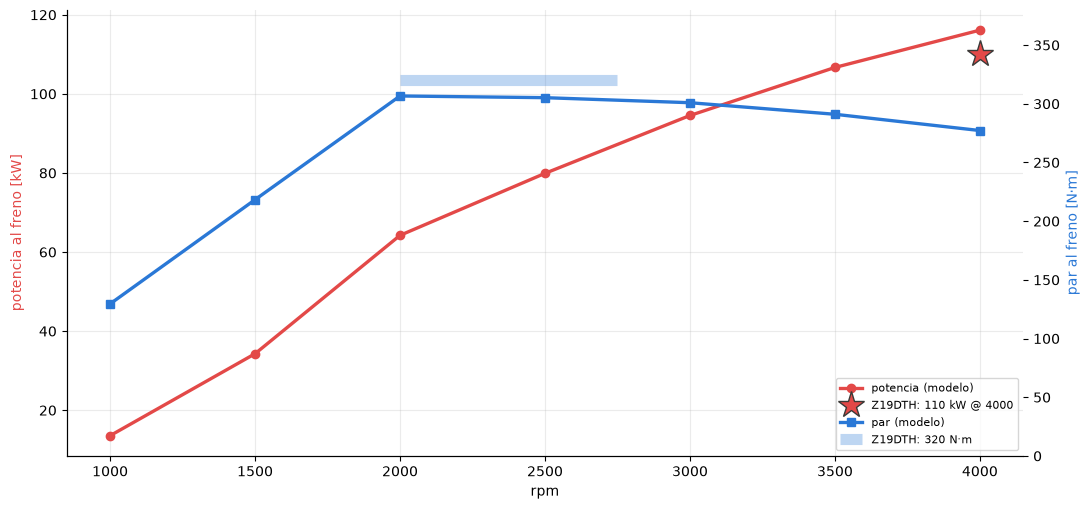

Modelo: 116.1 kW @ 4000 rpm (+5.6 % vs Z19DTH), par máx 307 N·m @ 2000 rpm (-4.2 %); BSFC mín 196 g/kWh


Output()

In [21]:
# WIDGET 8 — curva de par y potencia vs. rpm, contra el GM 1.9 CDTi de producción
def widget_curva(panel="par y potencia"):
    N = np.array([d["rpm"] for d in CURVA]); g = lambda k: np.array([d[k] for d in CURVA])
    fig, ax = plt.subplots(figsize=(11, 5.2))
    if panel == "par y potencia":
        ax.plot(N, g("pot")/1e3, "o-", color=COL["aviso"], lw=2.4, label="potencia (modelo)")
        ax.plot(Z19DTH["rpm_P"], Z19DTH["P_kW"], "*", ms=20, color=COL["aviso"], mec=COL["tinta"], label="Z19DTH: 110 kW @ 4000")
        ax.set_ylabel("potencia al freno [kW]", color=COL["aviso"])
        a2 = ax.twinx(); a2.plot(N, g("par"), "s-", color=COL["manivela"], lw=2.4, label="par (modelo)")
        a2.hlines(Z19DTH["par"], *Z19DTH["rpm_par"], color=COL["manivela"], lw=8, alpha=0.3, label="Z19DTH: 320 N·m")
        a2.set_ylabel("par al freno [N·m]", color=COL["manivela"]); a2.grid(False); a2.set_ylim(0, 380)
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower right")
    elif panel == "turbo":
        ax.plot(N, g("p_int")/1e5, "o-", color=COL["control"], lw=2.2, label="p admisión (3)")
        ax.plot(N, g("p5")/1e5, "s-", color=COL["caliente"], lw=2.2, label="p antes de turbina (5)")
        ax.axhline(ECU["p5_max"]/1e5, color=COL["caliente"], ls=":", label="límite TGV")
        ax.set_ylabel("p [bar abs]"); a2 = ax.twinx(); a2.plot(N, g("T5"), "^-", color=COL["gris"], label="T5 [K]"); a2.set_ylabel("T5 [K]"); a2.grid(False)
        ax.legend(fontsize=8, loc="lower right"); ax.set_title("el turbo no alcanza a bajas rpm: poca entalpía de escape")
    elif panel == "consumo y eficiencia":
        ax.plot(N, g("bsfc"), "o-", color=COL["CO2"] if "CO2" in COL else COL["NO"], lw=2.2, label="BSFC [g/kWh]"); ax.set_ylabel("BSFC [g/kWh]")
        a2 = ax.twinx(); a2.plot(N, g("eta_b")*100, "s-", color=COL["control"], label="η al freno [%]"); a2.set_ylabel("η_b [%]"); a2.grid(False)
        ax.legend(loc="upper left", fontsize=8); a2.legend(loc="upper right", fontsize=8)
    else:
        ax.plot(N, g("imep")/1e5, "o-", label="IMEP_g"); ax.plot(N, g("bmep")/1e5, "s-", label="BMEP")
        ax.plot(N, g("fmep")/1e5, "^-", label="FMEP"); ax.plot(N, g("pmep")/1e5, "v-", label="PMEP")
        ax.plot(N, g("pmax")/1e6, "d--", color=COL["aviso"], label="p_max / 10 [bar]"); ax.set_ylabel("bar"); ax.legend(fontsize=8)
    ax.set_xlabel("rpm"); plt.tight_layout(); plt.show()
    i = int(np.argmax(g("pot"))); j = int(np.argmax(g("par")))
    print(f"Modelo: {g('pot')[i]/1e3:.1f} kW @ {N[i]} rpm ({100*(g('pot')[i]/1e3 - 110)/110:+.1f} % vs Z19DTH), "
          f"par máx {g('par')[j]:.0f} N·m @ {N[j]} rpm ({100*(g('par')[j] - 320)/320:+.1f} %); BSFC mín {np.nanmin(g('bsfc')):.0f} g/kWh")

display(interactive_output(widget_curva, {"panel": ToggleButtons(options=["par y potencia", "turbo", "consumo y eficiencia", "presiones medias"], description="panel")}))

**Lectura.** La forma de la curva sale de tres límites físicos distintos, ninguno impuesto a mano:
- **Bajas rpm: el turbo.** Hay poca entalpía de escape, así que la turbina no puede pagar la compresión y el motor queda casi aspirado. Es el "agujero" bajo 1500 rpm que se siente al acelerar.
- **Rpm medias: el humo y el mapa de presión.** Con 2.3 bar de admisión y $\lambda$ = 1.45 el par queda en una **meseta**, como en el motor de producción.
- **Altas rpm: la fricción y el tiempo.** La FMEP crece con $N^2$ y la combustión ocupa más grados de cigüeñal, así que el par cae mientras la potencia sigue subiendo.

El modelo predice ~5 % menos par y ~5 % más potencia que el Z19DTH. Es coherente con su $r_c$ menor (15.8 frente a 17.5) y con un llenado ideal, sin pérdidas de flujo en las válvulas a alta velocidad.

## 11. ¿Es válido suponer ω constante? El volante y los 4 cilindros

Todo el modelo supone ω constante (cuasi-estático). La fluctuación real sale del par instantáneo y del momento de inercia del volante $I_v$:

$$\Delta E=\max_\theta\!\int_0^\theta\!(T-\bar T)\,d\theta'-\min_\theta(\cdot),\qquad C_s=\frac{\omega_{max}-\omega_{min}}{\bar\omega}\approx\frac{\Delta E}{I_v\bar\omega^2}$$

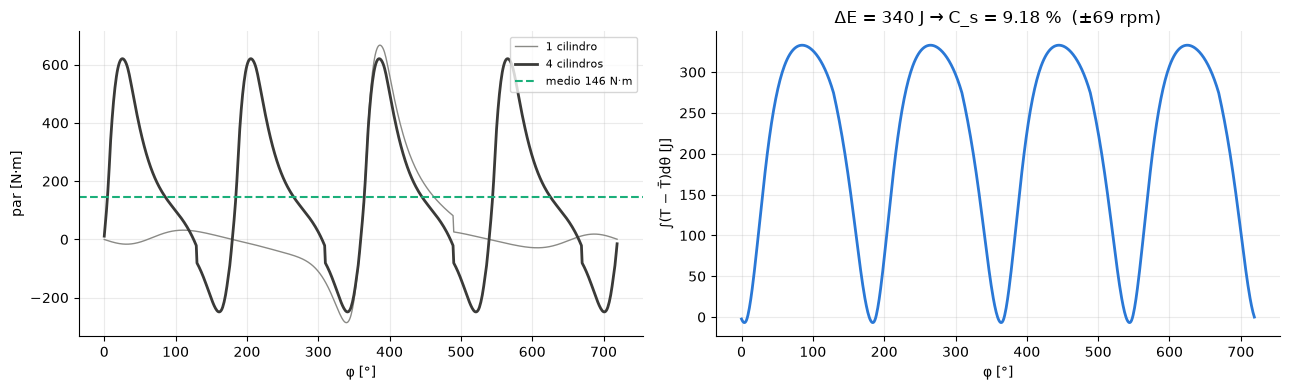

Output()

In [22]:
# WIDGET 9 — fluctuación de velocidad: 1, 2 o 4 cilindros y volante
def widget_volante(caso="SSE-17", I_v=0.15, n_cil=4, rpm=1500):
    c = C720[caso]; phi = c["phi"]; dphi = phi[1] - phi[0]
    w = 2*np.pi*rpm/60
    k = (w/(2*np.pi*c["rpm"]/60))**2
    T1 = c["par_gas"] + c["par_inercia"]*k           # la inercia escala con omega^2
    T = sum(np.roll(T1, -int(round(j*720/n_cil/dphi))) for j in range(n_cil)); Tm = T.mean()
    E = np.cumsum(T - Tm)*np.radians(dphi); dE = E.max() - E.min(); Cs = dE/(I_v*w**2)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(phi, T1, color=COL["gris"], lw=1, label="1 cilindro"); ax[0].plot(phi, T, color=COL["tinta"], lw=2, label=f"{n_cil} cilindros")
    ax[0].axhline(Tm, color=COL["control"], ls="--", label=f"medio {Tm:.0f} N·m"); ax[0].legend(fontsize=8); ax[0].set_xlabel("φ [°]"); ax[0].set_ylabel("par [N·m]")
    ax[1].plot(phi, E, color=COL["manivela"], lw=2); ax[1].set_xlabel("φ [°]"); ax[1].set_ylabel("∫(T − T̄)dθ [J]")
    ax[1].set_title(f"ΔE = {dE:.0f} J → C_s = {Cs*100:.2f} %  (±{Cs*rpm/2:.0f} rpm)")
    plt.tight_layout(); plt.show()

display(interactive_output(widget_volante, {
    "caso": Dropdown(options=list(C720), value="SSE-17", description="caso"),
    "I_v": FloatSlider(0.15, min=0.03, max=0.5, step=0.01, description="I_v [kg·m²]"),
    "n_cil": ToggleButtons(options=[1, 2, 4], value=4, description="cilindros"),
    "rpm": IntSlider(1500, min=800, max=4000, step=100, description="rpm")}))

**Lectura.** Con 4 cilindros y un volante típico ($I_v\approx$ 0.15 kg·m²) a 1500 rpm, $C_s$ queda en pocos por ciento: los tiempos que ve la química cambian en la misma proporción, y eso es menos que la incertidumbre de la mezcla o de Woschni. **El supuesto cuasi-estático se sostiene.** Con 1 cilindro $C_s$ se multiplica, y por eso los monocilíndricos llevan volantes relativamente enormes. A más rpm, el par de inercia de 4 cilindros (2.º armónico, §2) **no se cancela**: es la vibración vertical que obliga a los diésel de 4 cilindros grandes a usar ejes de balance.

## 12. Síntesis: diésel frente a Otto (NB10b)

Los dos motores modelados en el curso con la misma maquinaria (mecanismo 2D, química detallada, ECU explícita) permiten comparar las dos familias **por litro**, con la presión media efectiva:

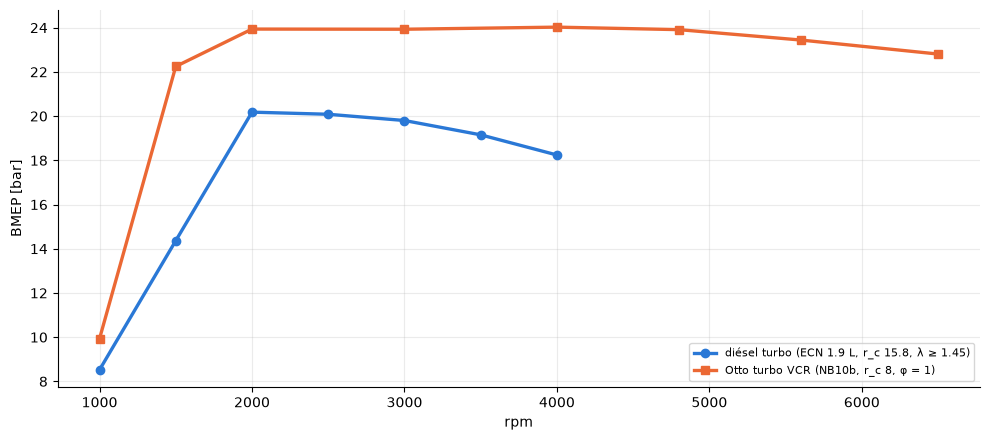

Output()

In [23]:
# WIDGET 10 — diésel (este cuadernillo) frente al Otto turbo VCR de NB10b, normalizados por cilindrada
ARCH_VCR = os.path.join("data", "vcr_resultados.json")
if not os.path.exists(ARCH_VCR):
    for rama in ("main", "nb10b-motor-vcr-integrado"):
        try:
            urllib.request.urlretrieve(REPO + rama + "/notebooks/data/vcr_resultados.json", ARCH_VCR); break
        except Exception:
            pass
VCR = json.load(open(ARCH_VCR))["curva"]["CR8"] if os.path.exists(ARCH_VCR) else None

def widget_comparar(magnitud="BMEP"):
    if VCR is None:
        print("No se encontraron los resultados de NB10b (data/vcr_resultados.json)."); return
    Nd = np.array([d["rpm"] for d in CURVA]); Nv = np.array([d["rpm"] for d in VCR])
    Vd_d, Vd_v = 4*A_P*STROKE, 1.997e-3
    if magnitud == "BMEP":
        yd = np.array([d["bmep"] for d in CURVA])/1e5; yv = np.array([d["par"] for d in VCR])*4*np.pi/Vd_v/1e5; lab = "BMEP [bar]"
    elif magnitud == "BSFC":
        yd = np.array([d["bsfc"] for d in CURVA]); yv = np.array([d["bsfc"] for d in VCR]); lab = "BSFC [g/kWh]"
    elif magnitud == "eficiencia al freno":
        yd = np.array([d["eta_b"] for d in CURVA])*100; yv = np.array([d["eta_b"] for d in VCR])*100; lab = "η_b [%]"
    else:
        yd = np.array([d["pmax"] for d in CURVA])/1e5; yv = np.array([d["pmax"] for d in VCR])/1e5; lab = "p_max [bar]"
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(Nd, yd, "o-", color=COL["manivela"], lw=2.4, label="diésel turbo (ECN 1.9 L, r_c 15.8, λ ≥ 1.45)")
    ax.plot(Nv, yv, "s-", color=COL["biela"], lw=2.4, label="Otto turbo VCR (NB10b, r_c 8, φ = 1)")
    ax.set_xlabel("rpm"); ax.set_ylabel(lab); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

display(interactive_output(widget_comparar, {"magnitud": ToggleButtons(options=["BMEP", "BSFC", "eficiencia al freno", "presión pico"], description="magnitud")}))

**Lectura.** El diésel consume **menos combustible por kWh** en todo el rango, por tres razones del §1: $r_c$ alta, carga controlada sin mariposa, y mezcla pobre con $k$ efectivo mayor. A cambio trabaja con presiones pico más altas y gira menos. El Otto turbo con VCR saca más BMEP a alta velocidad porque quema mezcla estequiométrica ($\phi$ = 1): aprovecha todo el oxígeno, mientras el diésel deja un 30 % sin usar para no producir humo. Son dos soluciones al mismo problema, cada una limitada por un fenómeno químico distinto: la **detonación** en el Otto y el **hollín** en el diésel.

## 13. 🎓 Resultados de la investigación original, reproducidos

1. **Informe de Estática (Alarcón y Chilatra), Cuadro 1** (rpm → vueltas en 2 s) y **§7.2** (sensibilidad de la cinética): con las **masas del Cuadro 5** a 100 rpm, ¿pesan las fuerzas de inercia frente a la del gas?
2. **Entrega diésel (Muñoz y Pedraza):** compresor de Euler (§3 y §10 de la entrega), intercooler ε-NTU para $N_p$ = 2, 4, 6 (§8) y transitorio de primer orden (§9), ya reproducidos en §4 de este cuadernillo; aquí se cuantifican las desviaciones.

In [24]:
# 1) Informe de Estática
print("1) Cuadro 1 — vueltas en 2 s:")
for rpm, ref in {100: 3.33, 500: 16.67, 1000: 33.33}.items():
    print(f"   {rpm:5d} rpm: {rpm/60*2:.4f} (informe {ref}, error {100*abs(rpm/60*2 - ref)/ref:.2f} %)")
th = np.radians(np.arange(-180, 180, 1.0))
for nombre, masas, rpm, p in [("Cuadro 5 (laboratorio)", dict(P=0.17663, B=0.10811), 100, 40e5), ("motor (supuesto)", MASAS, 1500, 40e5),
                              ("motor (supuesto)", MASAS, 4000, 40e5)]:
    w = 2*np.pi*rpm/60; Fg = p*A_P*np.ones_like(th)
    X, _ = newton_euler(th, w, Fg, masas, masas["B"]*ROD**2*0.075); X0, _ = newton_euler(th, w, Fg, dict(P=0, B=0), 0.0)
    print(f"   {nombre:24s} {rpm:5d} rpm: cambio máximo de |F_C| por la inercia = {np.max(np.abs(np.hypot(X[:,2],X[:,3]) - np.hypot(X0[:,2],X0[:,3])))/np.max(np.hypot(X0[:,2],X0[:,3]))*100:6.2f} % de la fuerza del gas")
print("   -> a 100 rpm (laboratorio) la inercia es despreciable, como concluyó el informe; en el motor real a 4000 rpm no lo es.")

# 2) Entrega diésel: desviaciones de la reproducción
print("\n2) Entrega diésel:")
e = compresor_euler_entrega(2*14.6917*250e3/42.43e6)
print(f"   Pi_C = {e['PI']:.4f} vs 2.2117 ({100*abs(e['PI'] - 2.2117)/2.2117:.3f} %), T2 = {e['T2_entrega']:.2f} vs 426.89 K ({100*abs(e['T2_entrega'] - 426.89)/426.89:.4f} %)")
for Np, ref, T3ref in zip([2, 4, 6], [0.2138, 0.3785, 0.5058], [399.33, 378.11, 361.70]):
    a = intercooler(426.89, 224.10e3, 0.1358, Np=Np, formula="carcasa")
    print(f"   Np = {Np}: eps {a['eps']:.4f} vs {ref} ({100*abs(a['eps'] - ref)/ref:.2f} %), T3 {a['T3']:.2f} vs {T3ref} K")
t = np.linspace(0, 180, 400); i30 = np.argmin(np.abs(t - 30))
a = intercooler(426.89, 224.10e3, 0.1358, Np=2, formula="carcasa")
print(f"   transitorio Np=2: T3(t≈τ) = {a['T3'] + (426.89 - a['T3'])*np.exp(-t[i30]/30):.4f} K vs 409.3929 K de la entrega")

1) Cuadro 1 — vueltas en 2 s:
     100 rpm: 3.3333 (informe 3.33, error 0.10 %)
     500 rpm: 16.6667 (informe 16.67, error 0.02 %)
    1000 rpm: 33.3333 (informe 33.33, error 0.01 %)
   Cuadro 5 (laboratorio)     100 rpm: cambio máximo de |F_C| por la inercia =   0.02 % de la fuerza del gas
   motor (supuesto)          1500 rpm: cambio máximo de |F_C| por la inercia =   7.05 % de la fuerza del gas
   motor (supuesto)          4000 rpm: cambio máximo de |F_C| por la inercia =  50.47 % de la fuerza del gas
   -> a 100 rpm (laboratorio) la inercia es despreciable, como concluyó el informe; en el motor real a 4000 rpm no lo es.

2) Entrega diésel:
   Pi_C = 2.2117 vs 2.2117 (0.002 %), T2 = 426.89 vs 426.89 K (0.0003 %)
   Np = 2: eps 0.2138 vs 0.2138 (0.01 %), T3 399.34 vs 399.33 K
   Np = 4: eps 0.3784 vs 0.3785 (0.02 %), T3 378.12 vs 378.11 K
   Np = 6: eps 0.5057 vs 0.5058 (0.02 %), T3 361.71 vs 361.7 K
   transitorio Np=2: T3(t≈τ) = 409.3968 K vs 409.3929 K de la entrega


## 14. Verificación

Cada verificación compara dos caminos **independientes** al mismo número (criterio < 1 %). La **validación** contra el motor real (§6) y contra el motor de producción (§10) se reporta aparte, con su desviación, porque mide el acierto del modelo físico y no la corrección del código.

In [25]:
# === Verificación ===================================================================
errores = {}
# 1) V(theta) de la cinemática vs. tabla del ECN (Crank-Slider Info)
vt = ECN["V_tabla"]; cad_v = np.array(vt["cad"]); dv = np.array(vt["dV_L"])*1e-3
errores["1) V(θ) vs. tabla ECN"] = 100*np.max(np.abs(A_P*(Y_PMS - cinematica(np.radians(cad_v))["y"]) - dv))/dv.max()
# 2) jacobiano vs. diferencias finitas
th = np.radians(np.arange(-180, 180, 0.5)); w = 2*np.pi*1500/60; h = 1e-6
k, kp, km = cinematica(th, w), cinematica(th + h, w), cinematica(th - h, w)
errores["2) velocidad (jacobiano)"] = 100*np.max(np.abs((kp["y"] - km["y"])/(2*h)*w - k["yd"]))/np.max(np.abs(k["yd"]))
errores["2) aceleración (jacobiano)"] = 100*np.max(np.abs((kp["yd"] - km["yd"])/(2*h)*w - k["ydd"]))/np.max(np.abs(k["ydd"]))
# 3) Newton-Euler vs. balance de potencia (con el ciclo real SSE-17)
c = C720["SSE-17"]; Fg = (c["p"] - P_CARTER)*A_P; X, _ = newton_euler(np.radians(c["cad"]), 2*np.pi*1500/60, Fg)
TP = par_por_potencia(np.radians(c["cad"]), 2*np.pi*1500/60, Fg)
errores["3) Newton-Euler vs. potencia"] = 100*np.max(np.abs(X[:, 7] - TP))/np.max(np.abs(TP))
# 4) cierre de la 1.a ley del ciclo cerrado
errores["4) cierre 1.a ley (SSE-7)"] = 100*abs(CASOS["SSE-7"]["cierre_1a_ley"])
# 5) c_p del aire: Cantera (NASA-7 del mecanismo) vs. CoolProp
gc = ct.Solution(MECH); err = []
for T in np.arange(300, 901, 100):
    gc.TPX = T, 1e5, X_AIRE; err.append(abs(gc.cp_mass/CP.PropsSI("CP0MASS", "T", T, "P", 1e5, "Air") - 1))
errores["5) c_p aire Cantera vs. CoolProp"] = 100*max(err)
# 6) compresor de la entrega reproducido
errores["6) Π_C entrega reproducida"] = 100*abs(compresor_euler_entrega(2*14.6917*250e3/42.43e6)["PI"] - 2.2117)/2.2117
# 7) intercooler de la entrega reproducido
errores["7) ε intercooler entrega"] = max(100*abs(intercooler(426.89, 224.10e3, 0.1358, Np=n, formula="carcasa")["eps"] - r)/r
                                           for n, r in zip([2, 4, 6], [0.2138, 0.3785, 0.5058]))
# 8) e-NTU de flujo cruzado: límite C_r -> 0 debe ser 1 - exp(-NTU)
errores["8) ε flujo cruzado (C_r→0)"] = 100*abs(eps_flujo_cruzado(1.3, 1e-6) - (1 - np.exp(-1.3)))/(1 - np.exp(-1.3))
# 9) [O]_e de la correlación vs. equilibrio químico de Cantera
ge = ct.Solution(MECH); ge.TPX = 900, 60e5, X_ECN; ge.set_equivalence_ratio(1.0, FUEL, X_ECN); ge.equilibrate("HP")
cc = ge.P/(8.314*ge.T)*1e-6; O_corr = 397.0*ge.T**-0.5*np.sqrt(ge["o2"].X[0]*cc)*np.exp(-31090/ge.T)
errores["9) [O]_e correlación vs. equilibrio"] = 100*abs(O_corr/(ge["o"].X[0]*cc) - 1)
# 10) poder calorífico inferior del n-heptano (termoquímica del mecanismo) vs. NIST (44.56 MJ/kg)
gl = ct.Solution(MECH); gl.TPX = 298.15, ct.one_atm, X_AIRE; gl.set_equivalence_ratio(1.0, FUEL, X_AIRE)
hr, Yf = gl.enthalpy_mass, gl[FUEL].Y[0]; X0 = gl.X; nF = X0[gl.species_index(FUEL)]
Xp = {"co2": 7*nF, "h2o": 8*nF, "n2": X0[gl.species_index("n2")], "o2": X0[gl.species_index("o2")] - 11*nF}
gl.TPX = 298.15, ct.one_atm, Xp; LHV_mec = (hr - gl.enthalpy_mass)/Yf
errores["10) LHV n-heptano vs. NIST"] = 100*abs(LHV_mec/44.56e6 - 1)
# 11) par medio por Newton-Euler vs. trabajo neto del ciclo / 4 pi
c = C720["SSE-7"]
errores["11) par medio NE vs. ∮p dV/4π"] = 100*abs(np.mean(c["par_gas"]) - np.trapezoid(np.append(c["p"], c["p"][0]) - P_CARTER, np.append(c["V"], c["V"][0]))/(4*np.pi))/abs(np.mean(c["par_gas"]))

for k_, v in errores.items():
    print(f"{k_:38s} error = {v:.4f} %   {'OK' if v < 1 else 'REVISAR'}")
print("\nTodos < 1 %:", all(v < 1 for v in errores.values()))
print(f"[validación ECN] p_max: " + ", ".join(f"{f[0]} {100*(f[1]-f[2])/f[2]:+.1f} %" for f in filas) +
      f" | rms de presión 1.6-2.1 bar | IMEPg +7-9 % (pérdidas del motor óptico no modeladas)")
i = int(np.argmax([d["pot"] for d in CURVA]))
print(f"[comparación Z19DTH] potencia máx {CURVA[i]['pot']/1e3:.1f} kW vs 110 kW ({100*(CURVA[i]['pot']/1e3 - 110)/110:+.1f} %); "
      f"par máx {max(d['par'] for d in CURVA):.0f} vs 320 N·m ({100*(max(d['par'] for d in CURVA) - 320)/320:+.1f} %)")

1) V(θ) vs. tabla ECN                  error = 0.0066 %   OK
2) velocidad (jacobiano)               error = 0.0000 %   OK
2) aceleración (jacobiano)             error = 0.0000 %   OK
3) Newton-Euler vs. potencia           error = 0.0000 %   OK
4) cierre 1.a ley (SSE-7)              error = 0.0130 %   OK
5) c_p aire Cantera vs. CoolProp       error = 0.9282 %   OK
6) Π_C entrega reproducida             error = 0.0017 %   OK
7) ε intercooler entrega               error = 0.0228 %   OK
8) ε flujo cruzado (C_r→0)             error = 0.0000 %   OK
9) [O]_e correlación vs. equilibrio    error = 0.1221 %   OK
10) LHV n-heptano vs. NIST             error = 0.8053 %   OK
11) par medio NE vs. ∮p dV/4π          error = 0.0065 %   OK

Todos < 1 %: True
[validación ECN] p_max: SSE-17 -0.8 %, SSE-7 +0.8 %, SSE+2 -0.9 % | rms de presión 1.6-2.1 bar | IMEPg +7-9 % (pérdidas del motor óptico no modeladas)
[comparación Z19DTH] potencia máx 116.1 kW vs 110 kW (+5.6 %); par máx 307 vs 320 N·m (-4.2 %)


## Conclusión

Un motor diésel es una **cadena causal**: sin chispa, la química del autoencendido obliga a comprimir mucho; la mezcla, no la llama, controla la combustión, así que el límite es el **humo** y no la detonación; y el turbo con intercooler mete más aire para quemar más combustible. El cuadernillo recorre esa cadena con un solo modelo: el mecanismo 2D del informe de Estática, la admisión forzada de la entrega diésel, química detallada del n-heptano integrada en el tiempo y una ECU explícita. Lo valida contra presiones y liberación de calor **medidas** en un motor real con datos abiertos, y predice la curva de un motor de producción con ~5 % de desviación.

Las limitaciones también enseñan: una zona de chorro homogénea subestima el pico premezclado de la inyección tardía, y el NO se reporta en tendencia. Ambas cosas son exactamente lo que resuelven los modelos multizona y CFD de la investigación de punta.

### Ejercicios de extensión
1. **Sensibilidad de la mezcla.** Repite la validación de §6 con $C_w$ = 0.25 y 0.35. ¿Qué caso se degrada más y por qué? (Pista: la inyección tardía ocurre con el aire enfriándose por la expansión.)
2. **Remolino.** Activa la corrección de remolino de Woschni (`swirl=2.2`) y compara la pérdida de calor con los 215 J que estima Sandia. ¿Por qué empeora la predicción del piloto tardío?
3. **Diseño de calibración.** Con la malla de §7, busca la combinación de avance y EGR que dé NO < 400 ppm con hollín ≤ 1.5 veces el caso base. ¿Qué pierdes en IMEP?
4. **Producción.** Cambia $V_c$ para $r_c$ = 17.5 (la del Z19DTH) en `punto()` y recalcula la curva. ¿Se acerca más al motor real? ¿Qué pasa con $p_{max}$?
5. **(De la entrega diésel)** Corrige el compresor de Euler ($T_2=T_1+\dot W/\dot m c_p$, $\Delta p$ con $\eta_C$) y recalcula el intercooler para $N_p$ = 2, 4, 6. ¿Cambia la conclusión sobre el número de pasos?

### Referencias
- Alarcón Benites, L. S. y Chilatra Ducuara, H. (2025). *Mecanismos de motores*, Estática, Entrega 3. Pontificia Universidad Javeriana.
- Muñoz, J. C. y Pedraza, S. G. (2026). *Modelamiento termo-fluido de un intercooler aire-aire acoplado a un motor diésel*. Máquinas Térmicas, Pontificia Universidad Javeriana.
- Engine Combustion Network, *Small-bore diesel engine* (Sandia National Laboratories). https://ecn.sandia.gov/engines/small-bore-diesel-engine/
- Perini, F., Busch, S. et al. (2019). Piston bowl geometry effects on combustion development in a high-speed light-duty diesel engine. SAE 2019-24-0167.
- Yoo, C. S., Lu, T., Chen, J. H. y Law, C. K. (2011). Direct numerical simulations of ignition of a lean n-heptane/air mixture... *Combustion and Flame* 158, 1727-1741.
- Naber, J. D. y Siebers, D. L. (1996). Effects of gas density and vaporization on penetration and dispersion of diesel sprays. SAE 960034.
- Hiroyasu, H. y Kadota, T. (1976). Models for combustion and formation of nitric oxide and soot in direct injection diesel engines. SAE 760129.
- Dec, J. E. (1997). A conceptual model of DI diesel combustion based on laser-sheet imaging. SAE 970873.
- Woschni, G. (1967). A universally applicable equation for the instantaneous heat transfer coefficient in the internal combustion engine. SAE 670931.
- Livengood, J. C. y Wu, P. C. (1955). Correlation of autoignition phenomena in internal combustion engines and rapid compression machines. *Symp. (Int.) Combust.* 5, 347-356.
- Heywood, J. B. (2018). *Internal Combustion Engine Fundamentals*, 2.ª ed. McGraw-Hill.
- Incropera, F. P. et al. (2007). *Fundamentals of Heat and Mass Transfer*, 6.ª ed. Wiley.